# 06 — Đánh giá test, chi phí và phân tích lỗi: ConvNeXt-Tiny vs ResNet18 (CIFAR-10)

**Mục tiêu:** đọc đúng **2 run đã chốt trong `reports/run_manifest.csv`**, đánh giá trên test set, đo chi phí,
rồi so sánh *chất lượng ↔ chi phí*, *lớp dễ nhầm* và *ví dụ lỗi* của hai model.

**Nguyên tắc**
- Chỉ đọc artifacts đã lưu, **không huấn luyện lại**. Test set chỉ dùng để đánh giá cuối, không dùng để chọn epoch/hyperparameter.
- Run lấy từ manifest (không gõ tay tên run). Notebook dừng nếu manifest không đúng 2 run, thiếu file hoặc SHA256 không khớp.
- **Số tham số = đếm trực tiếp** trên model 10 lớp của checkpoint. Con số 11.7M / 28.6M của torchvision chỉ là tham chiếu ImageNet-1000.
- **Nhãn chi phí ghi đúng bản chất phép đo:** FLOPs tham chiếu ≠ FLOPs đo trực tiếp; latency là thời gian **cả batch 32 ảnh** (forward-only), không phải 1 ảnh.

**Điều kiện chạy:** có `best.pt` của 2 run trong manifest, `configs/default.json`, dữ liệu CIFAR-10 ở `data/raw`, `data/splits/split_indices.json`.

> ⚠️ Các con số của bản notebook cũ (accuracy 0.9644 / 0.9824…) thuộc các run **20261112_…**, không phải 2 run trong manifest
> (`…seed42_20261117_…`). Cần chạy lại notebook này để có số liệu đúng run đã chốt.

## 1. Thiết lập môi trường
Thêm project root vào `sys.path` rồi import các module của package `src.cifar_compare`.

In [3]:
import csv
import hashlib
import json
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Tìm project root từ thư mục hiện tại hoặc các thư mục cha.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (p for p in candidates if (p / "src/cifar_compare/evaluate.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Không tìm thấy project root (cần có src/cifar_compare/evaluate.py). "
                       "Hãy chạy notebook bên trong project.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch, torchvision
from torchvision.datasets import CIFAR10

from src.cifar_compare.evaluate import evaluate_checkpoint
from src.cifar_compare.models import build_model, count_parameters
from src.cifar_compare.profiling import profile_model
from src.cifar_compare.visualize import visualize_all   # lưu ý: module này đặt matplotlib backend = Agg
from src.cifar_compare.utils import load_config

print(f"Project root: {PROJECT_ROOT}")
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Màu cố định cho 2 model ở mọi hình trong notebook
COLORS = {"resnet18": "#2a6fbb", "convnext_tiny": "#e07b22"}
LABELS = {"resnet18": "ResNet18", "convnext_tiny": "ConvNeXt-Tiny"}
MODELS = ("resnet18", "convnext_tiny")


def show_fig(fig, path):
    # Lưu rồi hiển thị bằng Image(...) để không phụ thuộc backend Agg do visualize.py đặt.
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))
    print(f"-> {path}")

Project root: d:\Môn năm 3\ConvNeXt_ResNet18_tren_CIFAR-10\ConvNeXtiny_vs_ResNet18_A_Comparative_Study_on_CIFAR10_Classification
torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | CUDA: True
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 2. Đọc đúng 2 run từ manifest
`reports/run_manifest.csv` là nguồn duy nhất cho tên run / checkpoint. Các kiểm tra bên dưới gom **tất cả** lỗi rồi mới dừng:
- đúng 2 dòng: `resnet18` và `convnext_tiny`, `status = selected_reload_verified`;
- cùng `protocol_id`, `seed`, `weights`, `input_size`, `split_sha256`;
- file tồn tại, **SHA256** của `best.pt` và của split khớp manifest;
- `summary.json` khớp `best_epoch` / `best_val_accuracy` trong manifest.

In [4]:
DEFAULTS = {
    "data_root": "data/raw", "split_path": "data/splits/split_indices.json",
    "seed": 42, "val_size": 5000, "input_size": 224, "batch_size": 32, "num_workers": 4,
    "output_dir": "artifacts", "device": "auto", "eval_batch_size": 64,
    "warmup": 20, "repeats": 100,
}
config = load_config(PROJECT_ROOT / "configs/default.json", DEFAULTS)
MANIFEST_PATH = PROJECT_ROOT / "reports/run_manifest.csv"
EXPECTED_STATUS = "selected_reload_verified"


def as_path(p):
    # Manifest có thể ghi đường dẫn kiểu Windows (\) -> chuẩn hoá về đường dẫn trong project.
    return PROJECT_ROOT / Path(str(p).replace("\\", "/"))


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


with open(MANIFEST_PATH, encoding="utf-8-sig", newline="") as f:
    manifest_rows = list(csv.DictReader(f))

errors = []
def check(cond, msg):
    if not cond:
        errors.append(msg)

check(len(manifest_rows) == 2, f"Manifest phải có đúng 2 run, hiện có {len(manifest_rows)}.")
by_model = {r["model"]: r for r in manifest_rows}
check(set(by_model) == set(MODELS) and len(by_model) == len(manifest_rows),
      f"Manifest phải có đúng {MODELS}, hiện có {[r['model'] for r in manifest_rows]}.")
if errors:
    raise RuntimeError("\n".join(errors))

for key in ("protocol_id", "seed", "weights", "input_size", "split_sha256"):
    vals = {by_model[m][key] for m in MODELS}
    check(len(vals) == 1, f"Hai run khác nhau ở cột '{key}': {vals}")

RUNS, CHECKPOINT_PATHS, RUN_CFG, RUN_SUMMARY, CKPT_SHA = {}, {}, {}, {}, {}
split_path = as_path(by_model["resnet18"]["split_path"])
check(split_path.is_file(), f"Không thấy split: {split_path}")
if split_path.is_file():
    check(sha256_file(split_path) == by_model["resnet18"]["split_sha256"], "SHA256 của split không khớp manifest.")

for m in MODELS:
    r = by_model[m]
    check(r["status"] == EXPECTED_STATUS, f"{m}: status = {r['status']!r}, cần {EXPECTED_STATUS!r}.")
    RUNS[m] = r["run_name"]
    ckpt = as_path(r["best_checkpoint"])
    CHECKPOINT_PATHS[m] = ckpt
    check(ckpt.parent.name == r["run_name"], f"{m}: thư mục checkpoint ({ckpt.parent.name}) ≠ run_name ({r['run_name']}).")
    if not ckpt.is_file():
        errors.append(f"{m}: không thấy checkpoint {ckpt}"); continue
    CKPT_SHA[m] = sha256_file(ckpt)
    check(CKPT_SHA[m] == r["best_checkpoint_sha256"], f"{m}: SHA256 best.pt không khớp manifest.")
    for key, store in (("config_path", RUN_CFG), ("summary_path", RUN_SUMMARY)):
        p = as_path(r[key])
        if not p.is_file():
            errors.append(f"{m}: không thấy {p}"); continue
        store[m] = json.load(open(p, encoding="utf-8"))
    if m in RUN_SUMMARY:
        s = RUN_SUMMARY[m]
        check(int(s["best_epoch"]) == int(r["best_epoch"]), f"{m}: best_epoch summary ≠ manifest.")
        check(abs(float(s["best_val_accuracy"]) - float(r["best_val_accuracy"])) < 1e-6, f"{m}: best_val_accuracy summary ≠ manifest.")
    if m in RUN_CFG:
        check(int(RUN_CFG[m]["input_size"]) == int(r["input_size"]), f"{m}: input_size trong config.json ≠ manifest.")

if errors:
    raise RuntimeError("Manifest/artifacts không hợp lệ:\n- " + "\n- ".join(errors))

df_manifest = pd.DataFrame([by_model[m] for m in MODELS])[
    ["model", "run_name", "best_epoch", "best_val_accuracy", "best_val_loss", "status", "test_evaluated"]]
print("✓ Manifest hợp lệ: đúng 2 run, file tồn tại, SHA256 khớp.")
print(f"  protocol={by_model['resnet18']['protocol_id']} | seed={by_model['resnet18']['seed']} | split SHA256={by_model['resnet18']['split_sha256'][:12]}…")
display(df_manifest)

✓ Manifest hợp lệ: đúng 2 run, file tồn tại, SHA256 khớp.
  protocol=cifar10-baseline-v1 | seed=42 | split SHA256=4d6d124366ad…


,model,run_name,best_epoch,best_val_accuracy,best_val_loss,status,test_evaluated
0,resnet18,resnet18_seed42_20261117_175014_404116,10,0.9658,0.1286797357559204,selected_reload_verified,false
1,convnext_tiny,convnext_tiny_seed42_20261117_191514_964199,9,0.985,0.06743563089370727,selected_reload_verified,false


## 3. Số tham số thực tế (đếm trực tiếp trên checkpoint)
Với mỗi `best.pt`: nạp `state_dict` (strict) vào model 10 lớp và **đếm bằng `count_parameters`**. Đối chiếu chéo với:
- `total_parameters` đã ghi trong `config.json` của run lúc training;
- epoch / tên model trong checkpoint so với manifest;
- số tham số model ImageNet-1000 lớp (đếm trực tiếp, không gõ tay) — để thấy chênh lệch chỉ do head.

In [5]:
PARAMS, CKPT_META = {}, {}
for m in MODELS:
    ckpt = torch.load(CHECKPOINT_PATHS[m], map_location="cpu", weights_only=False)
    row = by_model[m]
    errs = []
    if ckpt["model_name"] != m:                 errs.append(f"model_name trong ckpt = {ckpt['model_name']}")
    if int(ckpt["epoch"]) != int(row["best_epoch"]): errs.append(f"epoch trong ckpt = {ckpt['epoch']} ≠ manifest {row['best_epoch']}")
    if abs(float(ckpt["best_val_accuracy"]) - float(row["best_val_accuracy"])) > 1e-6: errs.append("best_val_accuracy trong ckpt ≠ manifest")
    if errs:
        raise RuntimeError(f"{m}: checkpoint không khớp manifest: {errs}")

    net = build_model(m, num_classes=int(ckpt["num_classes"]), pretrained=False)
    net.load_state_dict(ckpt["model_state_dict"])        # strict=True
    head = net.classifier[-1] if m == "convnext_tiny" else net.fc
    ref1000 = build_model(m, num_classes=1000, pretrained=False)

    total = count_parameters(net)
    PARAMS[m] = {
        "total": total,
        "trainable": count_parameters(net, trainable_only=True),
        "head": sum(p.numel() for p in head.parameters()),
        "imagenet1000": count_parameters(ref1000),
    }
    logged = RUN_CFG[m].get("total_parameters")
    if logged is not None and int(logged) != total:
        raise RuntimeError(f"{m}: đếm được {total:,} ≠ total_parameters trong config.json của run ({logged:,}).")
    CKPT_META[m] = {"epoch": int(ckpt["epoch"]), "weights": ckpt.get("weights"),
                    "class_names": list(ckpt["class_names"]), "input_size": int(ckpt["config"]["input_size"])}
    del ckpt, net, ref1000

df_params = pd.DataFrame(PARAMS).T
df_params.index.name = "Model"
df_params = df_params.rename(columns={
    "total": "Params thực tế (model 10 lớp)", "trainable": "Trainable (thực tế)",
    "head": "Trong đó head 10 lớp", "imagenet1000": "Tham chiếu ImageNet-1000 lớp (đếm trực tiếp)"})
display(df_params.map(lambda v: f"{v:,}"))
for m in MODELS:
    d = PARAMS[m]["imagenet1000"] - PARAMS[m]["total"]
    print(f"{LABELS[m]}: ImageNet-1000 − 10 lớp = {d:,} tham số (chỉ do đổi head). Khớp log training: ✓")

,Params thực tế (model 10 lớp),Trainable (thực tế),Trong đó head 10 lớp,Tham chiếu ImageNet-1000 lớp (đếm trực tiếp)
Model,,,,
resnet18,"11,181,642","11,181,642","5,130","11,689,512"
convnext_tiny,"27,827,818","27,827,818","7,690","28,589,128"


ResNet18: ImageNet-1000 − 10 lớp = 507,870 tham số (chỉ do đổi head). Khớp log training: ✓
ConvNeXt-Tiny: ImageNet-1000 − 10 lớp = 761,310 tham số (chỉ do đổi head). Khớp log training: ✓


## 4. Đánh giá trên test set (10.000 ảnh, chỉ checkpoint validation-best)
Nếu đã có `test_metrics.json` + `test_predictions.npz` của đúng run/checkpoint thì **dùng lại** (không chạm test lần nữa);
đặt `FORCE_REEVAL = True` để đánh giá lại. Kết quả lưu ở `artifacts/logs/<run>/` và `artifacts/predictions/<run>/`.

In [6]:
FORCE_REEVAL = False
OUT = Path(config["output_dir"])


def load_or_evaluate(m):
    run = RUNS[m]
    mpath = OUT / "logs" / run / "test_metrics.json"
    ppath = OUT / "predictions" / run / "test_predictions.npz"
    if not FORCE_REEVAL and mpath.is_file() and ppath.is_file():
        saved = json.load(open(mpath, encoding="utf-8"))
        same_ckpt = str(saved.get("checkpoint", "")).replace("\\", "/").endswith(f"checkpoints/{run}/best.pt")
        if same_ckpt and saved.get("model") == m and saved.get("num_samples") == 10000:
            print(f"[reuse] {m}: dùng lại {mpath}")
            return saved
    print(f"[evaluate] {m}: đánh giá {CHECKPOINT_PATHS[m]}")
    return evaluate_checkpoint(CHECKPOINT_PATHS[m], config, output_dir=config["output_dir"], device=None)


test_metrics = {m: load_or_evaluate(m) for m in MODELS}

for m in MODELS:
    t = test_metrics[m]
    print(f"{LABELS[m]:14s} acc={t['accuracy']:.4f} | macro-F1={t['macro_f1']:.4f} | loss={t['loss']:.4f} | n={t['num_samples']}")

[reuse] resnet18: dùng lại artifacts\logs\resnet18_seed42_20261117_175014_404116\test_metrics.json
[reuse] convnext_tiny: dùng lại artifacts\logs\convnext_tiny_seed42_20261117_191514_964199\test_metrics.json
ResNet18       acc=0.9626 | macro-F1=0.9625 | loss=0.1390 | n=10000
ConvNeXt-Tiny  acc=0.9825 | macro-F1=0.9825 | loss=0.0706 | n=10000


## 5. Chi phí tính toán — cách đo và cách gắn nhãn
Điều kiện đo (theo protocol đã chốt với Quy): `[32,3,224,224]`, float32, eval + no_grad, 20 warm-up / 100 lần đo, CUDA Events + synchronize, **chỉ forward** (không data loading).

**Cách gắn nhãn trong các bảng**
| Nhãn | Nguồn | Ý nghĩa đúng |
|---|---|---|
| **Params thực tế (M)** | đếm trực tiếp ở mục 3 | model 10 lớp, đúng cái được đánh giá |
| **FLOPs tham chiếu (G)** | hằng số torchvision (ImageNet-1K, 224², batch 1) | *không đo trên model 10 lớp*; chỉ để đối chiếu với tài liệu |
| **FLOPs đo trực tiếp (G)** | `torch.utils.flop_counter`, `[1,3,224,224]`, model 10 lớp, **1 MAC = 2 FLOPs** | chỉ đếm conv/matmul; bỏ qua norm/activation |
| **Latency / batch 32 (ms)** | CUDA Events, forward-only | thời gian **cả batch 32 ảnh** |
| **Latency quy đổi / ảnh (ms)** | latency batch ÷ 32 | chỉ là *quy đổi*; chưa phải latency ảnh đơn (chưa đo batch=1) |
| **Throughput (ảnh/s)** | 32 ÷ latency mean | forward-only, batch 32 |
| **Peak mem (MB)** | `max_memory_allocated` | bộ nhớ tensor PyTorch, không phải toàn bộ VRAM |

In [7]:
profile_results = {}
for m in MODELS:
    print(f"\n{'='*70}\nProfiling: {m}\n{'='*70}")
    profile_results[m] = profile_model(m, config, device=None)

# Hai model phải được đo cùng điều kiện
keys = ("input_size", "batch_size", "device", "gpu_name", "dtype", "cudnn_benchmark", "tf32_matmul", "tf32_cudnn")
for k in keys:
    vals = {str(profile_results[m][k]) for m in MODELS}
    assert len(vals) == 1, f"Điều kiện đo khác nhau ở '{k}': {vals}"
for m in MODELS:   # số tham số trong profiling phải trùng số đếm từ checkpoint
    assert profile_results[m]["params_total_actual"] == PARAMS[m]["total"], f"{m}: params profiling ≠ checkpoint"
print("\n✓ Cùng điều kiện đo cho cả hai model:", {k: profile_results['resnet18'][k] for k in keys})


Profiling: resnet18
[profiling] GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
[profiling] VRAM: 12.8 GB | sm_120
[profiling] resnet18: Latency mean=9.64ms p95=11.00ms | Throughput=3318.6 samples/s | Peak Mem=285MB
[profiling] Đã lưu: artifacts\profiling\resnet18_profile.json

Profiling: convnext_tiny
[profiling] GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
[profiling] VRAM: 12.8 GB | sm_120
[profiling] convnext_tiny: Latency mean=42.93ms p95=48.71ms | Throughput=745.5 samples/s | Peak Mem=503MB
[profiling] Đã lưu: artifacts\profiling\convnext_tiny_profile.json

✓ Cùng điều kiện đo cho cả hai model: {'input_size': 224, 'batch_size': 32, 'device': 'cuda', 'gpu_name': 'NVIDIA GeForce RTX 5070 Ti Laptop GPU', 'dtype': 'torch.float32', 'cudnn_benchmark': False, 'tf32_matmul': False, 'tf32_cudnn': True}


In [8]:
def count_flops_direct(model_name, input_size=224):
    # Đếm FLOPs trực tiếp trên model 10 lớp, batch=1. Trả về GFLOPs (1 MAC = 2 FLOPs) hoặc None nếu không hỗ trợ.
    try:
        from torch.utils.flop_counter import FlopCounterMode
    except ImportError:
        return None
    net = build_model(model_name, num_classes=10, pretrained=False).eval()
    x = torch.randn(1, 3, input_size, input_size)
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        net(x)
    return fc.get_total_flops() / 1e9


FLOPS_DIRECT = {m: count_flops_direct(m, int(profile_results[m]["input_size"])) for m in MODELS}
for m in MODELS:
    ref, direct = profile_results[m]["flops_gflops"], FLOPS_DIRECT[m]
    if direct:
        print(f"{LABELS[m]:14s} tham chiếu torchvision = {ref:.2f} G | đo trực tiếp (1 MAC = 2 FLOPs) = {direct:.2f} G | tỷ lệ = {direct/ref:.2f}")
print("\nNếu tỷ lệ ≈ 2: con số torchvision đang theo quy ước 1 MAC = 1 FLOP (≈ GMACs). Hai cột KHÔNG được trộn với nhau; "
      "khi viết báo cáo hãy nêu rõ quy ước đang dùng.")

W1123 17:00:07.567000 23344 venv\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


ResNet18       tham chiếu torchvision = 1.81 G | đo trực tiếp (1 MAC = 2 FLOPs) = 3.63 G | tỷ lệ = 2.00
ConvNeXt-Tiny  tham chiếu torchvision = 4.46 G | đo trực tiếp (1 MAC = 2 FLOPs) = 8.91 G | tỷ lệ = 2.00

Nếu tỷ lệ ≈ 2: con số torchvision đang theo quy ước 1 MAC = 1 FLOP (≈ GMACs). Hai cột KHÔNG được trộn với nhau; khi viết báo cáo hãy nêu rõ quy ước đang dùng.


In [9]:
def build_cost_table():
    rows = []
    for m in MODELS:
        p, lat = profile_results[m], profile_results[m]["latency"]
        b = p["batch_size"]
        rows.append({
            "Model": m,
            "Params thực tế (M)": PARAMS[m]["total"] / 1e6,
            "FLOPs tham chiếu ImageNet (G)": p["flops_gflops"],
            "FLOPs đo trực tiếp 2×MAC (G)": FLOPS_DIRECT[m],
            f"Latency/batch {b} mean (ms)": lat["mean_ms"],
            f"Latency/batch {b} p50 (ms)": lat["p50_ms"],
            f"Latency/batch {b} p95 (ms)": lat["p95_ms"],
            f"Latency/batch {b} std (ms)": lat["std_ms"],
            "Latency quy đổi/ảnh (ms)": lat["mean_ms"] / b,
            "Throughput (ảnh/s)": p["throughput_samples_per_sec"],
            "Peak mem (MB)": p["peak_memory_mb"],
        })
    return pd.DataFrame(rows).set_index("Model")

df_cost = build_cost_table().apply(pd.to_numeric, errors="coerce")   # CPU: peak mem = None -> NaN
print(f"BẢNG CHI PHÍ — {profile_results['resnet18']['gpu_name']}, input {profile_results['resnet18']['input_size']}², "
      f"batch {profile_results['resnet18']['batch_size']}, {profile_results['resnet18']['dtype']}, forward-only")
display(df_cost.round(3))
print("Ghi chú: 'Latency quy đổi/ảnh' = mean ÷ batch, không phải latency ảnh đơn. FLOPs tham chiếu không đo trên model 10 lớp.")
jit = {m: profile_results[m]["latency"]["p95_ms"] / profile_results[m]["latency"]["mean_ms"] for m in MODELS}
print("p95/mean:", {LABELS[m]: round(v, 2) for m, v in jit.items()},
      "→ nếu >1.3 thì GPU laptop dao động (nhiệt/xung); nên đọc p50 và cân nhắc đo lại.")

BẢNG CHI PHÍ — NVIDIA GeForce RTX 5070 Ti Laptop GPU, input 224², batch 32, torch.float32, forward-only


,Params thực tế (M),FLOPs tham chiếu ImageNet (G),FLOPs đo trực tiếp 2×MAC (G),Latency/batch 32 mean (ms),Latency/batch 32 p50 (ms),Latency/batch 32 p95 (ms),Latency/batch 32 std (ms),Latency quy đổi/ảnh (ms),Throughput (ảnh/s),Peak mem (MB)
Model,,,,,,,,,,
resnet18,11.182,1.81,3.627,9.643,9.147,10.998,0.761,0.301,3318.556,284.618
convnext_tiny,27.828,4.46,8.910,42.926,42.051,48.710,2.981,1.341,745.465,503.163


Ghi chú: 'Latency quy đổi/ảnh' = mean ÷ batch, không phải latency ảnh đơn. FLOPs tham chiếu không đo trên model 10 lớp.
p95/mean: {'ResNet18': 1.14, 'ConvNeXt-Tiny': 1.13} → nếu >1.3 thì GPU laptop dao động (nhiệt/xung); nên đọc p50 và cân nhắc đo lại.


## 6. Hình từ artifacts đã lưu
`visualize_all` tạo learning curves, confusion matrix (đếm + chuẩn hoá), ảnh sai confidence cao nhất và per-class F1 vào `artifacts/figures/<run>/`.
Phần so sánh hai model nằm ở các mục 8–10.


resnet18_seed42_20261117_175014_404116
[visualize] Learning curves -> artifacts\figures\resnet18_seed42_20261117_175014_404116\learning_curves.png
[visualize] Confusion matrix (count) -> artifacts\figures\resnet18_seed42_20261117_175014_404116\confusion_matrix.png
[visualize] Confusion matrix (norm) -> artifacts\figures\resnet18_seed42_20261117_175014_404116\confusion_matrix_normalized.png
[visualize] Misclassified -> artifacts\figures\resnet18_seed42_20261117_175014_404116\misclassified.png
[visualize] Per-class F1 -> artifacts\figures\resnet18_seed42_20261117_175014_404116\per_class_f1.png
[visualize] Manifest -> artifacts\figures\resnet18_seed42_20261117_175014_404116\manifest.json


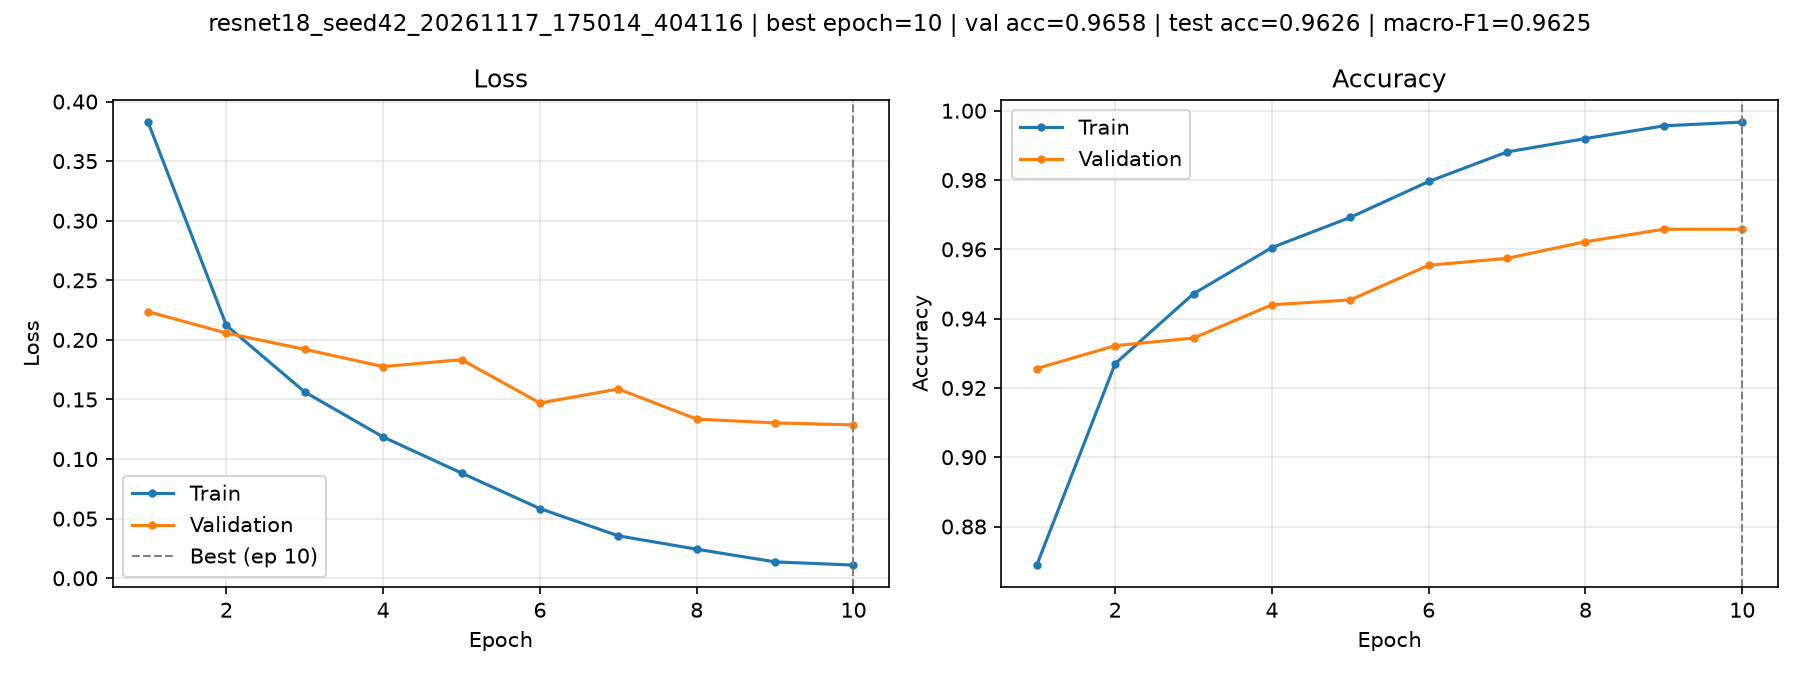


convnext_tiny_seed42_20261117_191514_964199
[visualize] Learning curves -> artifacts\figures\convnext_tiny_seed42_20261117_191514_964199\learning_curves.png
[visualize] Confusion matrix (count) -> artifacts\figures\convnext_tiny_seed42_20261117_191514_964199\confusion_matrix.png
[visualize] Confusion matrix (norm) -> artifacts\figures\convnext_tiny_seed42_20261117_191514_964199\confusion_matrix_normalized.png
[visualize] Misclassified -> artifacts\figures\convnext_tiny_seed42_20261117_191514_964199\misclassified.png
[visualize] Per-class F1 -> artifacts\figures\convnext_tiny_seed42_20261117_191514_964199\per_class_f1.png
[visualize] Manifest -> artifacts\figures\convnext_tiny_seed42_20261117_191514_964199\manifest.json


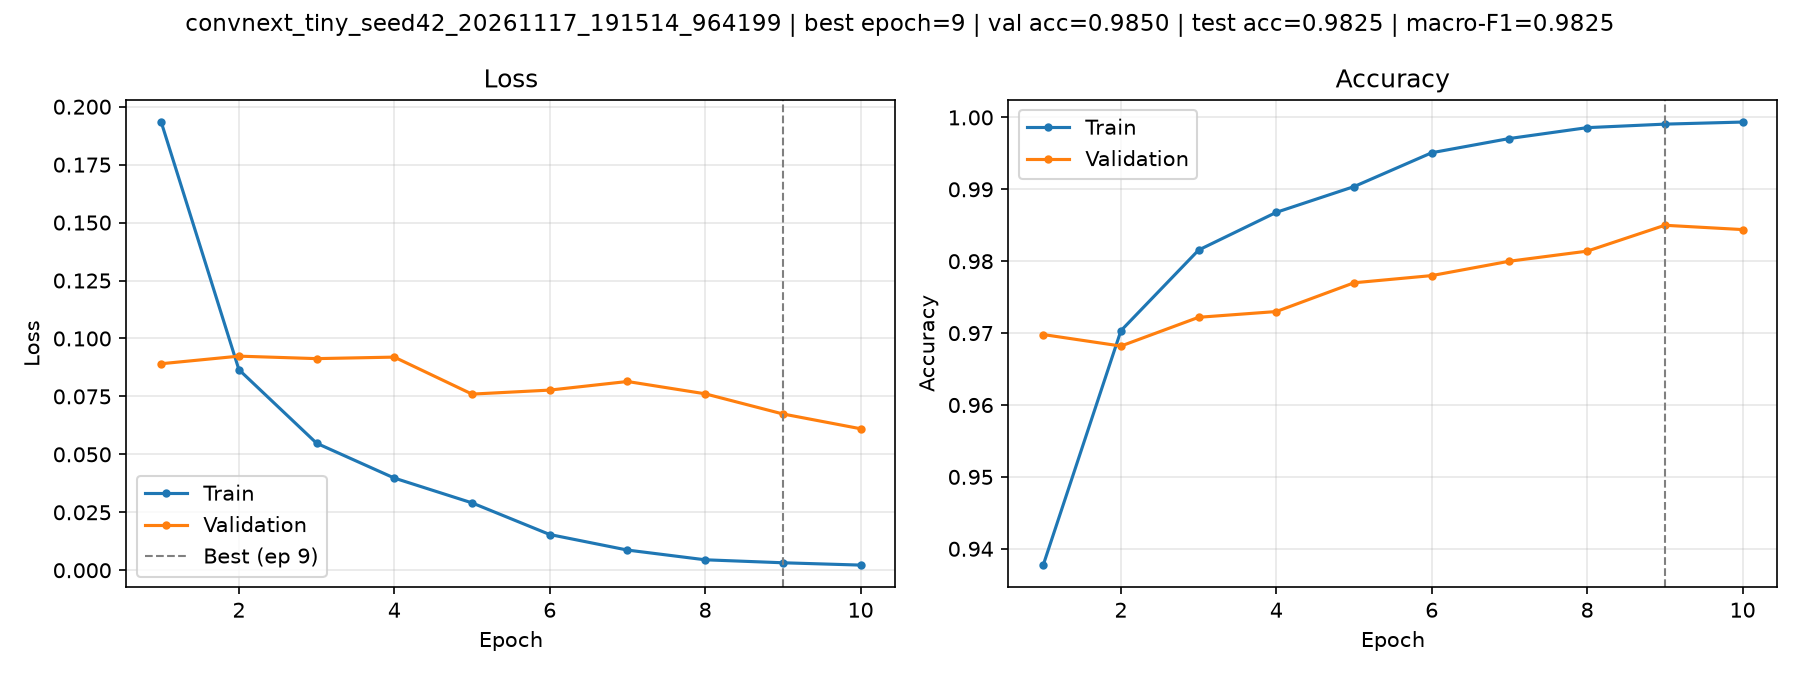

In [10]:
for m in MODELS:
    print(f"\n{'='*70}\n{RUNS[m]}\n{'='*70}")
    visualize_all(RUNS[m], config)
    display(Image(filename=str(OUT / "figures" / RUNS[m] / "learning_curves.png")))

## 7. Bảng chất lượng trên test

In [11]:
def class_list(per_class):
    return [c for c in per_class if c not in ("accuracy", "macro avg", "weighted avg")]

CLASS_NAMES = class_list(test_metrics["resnet18"]["per_class"])
assert CLASS_NAMES == class_list(test_metrics["convnext_tiny"]["per_class"]) == CKPT_META["resnet18"]["class_names"]

rows = []
for m in MODELS:
    t = test_metrics[m]
    row = {"Model": m, "Test Accuracy": t["accuracy"], "Macro-F1": t["macro_f1"], "Test Loss": t["loss"]}
    row.update({f"F1_{c}": t["per_class"][c]["f1-score"] for c in CLASS_NAMES})
    rows.append(row)
df_test = pd.DataFrame(rows).set_index("Model")
print("BẢNG: KẾT QUẢ TEST CIFAR-10 (10.000 ảnh, checkpoint validation-best theo manifest)")
display(df_test.round(4))

pc = pd.DataFrame({
    "P_resnet18":  {c: test_metrics["resnet18"]["per_class"][c]["precision"] for c in CLASS_NAMES},
    "R_resnet18":  {c: test_metrics["resnet18"]["per_class"][c]["recall"] for c in CLASS_NAMES},
    "F1_resnet18": {c: test_metrics["resnet18"]["per_class"][c]["f1-score"] for c in CLASS_NAMES},
    "P_convnext":  {c: test_metrics["convnext_tiny"]["per_class"][c]["precision"] for c in CLASS_NAMES},
    "R_convnext":  {c: test_metrics["convnext_tiny"]["per_class"][c]["recall"] for c in CLASS_NAMES},
    "F1_convnext": {c: test_metrics["convnext_tiny"]["per_class"][c]["f1-score"] for c in CLASS_NAMES},
})
pc["ΔF1 (ConvNeXt − ResNet)"] = pc["F1_convnext"] - pc["F1_resnet18"]
print("\nPer-class precision / recall / F1:")
display(pc.round(3))

BẢNG: KẾT QUẢ TEST CIFAR-10 (10.000 ảnh, checkpoint validation-best theo manifest)


,Test Accuracy,Macro-F1,Test Loss,F1_airplane,F1_automobile,F1_bird,F1_cat,F1_deer,F1_dog,F1_frog,F1_horse,F1_ship,F1_truck
Model,,,,,,,,,,,,,
resnet18,0.9626,0.9625,0.1390,0.9745,0.9760,0.9548,0.9172,0.9684,0.9284,0.9796,0.978,0.9791,0.9695
convnext_tiny,0.9825,0.9825,0.0706,0.9860,0.9855,0.9825,0.9635,0.9870,0.9673,0.9915,0.991,0.9890,0.9816



Per-class precision / recall / F1:


,P_resnet18,R_resnet18,F1_resnet18,P_convnext,R_convnext,F1_convnext,ΔF1 (ConvNeXt − ResNet)
airplane,0.974,0.975,0.975,0.985,0.987,0.986,0.012
automobile,0.977,0.975,0.976,0.988,0.983,0.985,0.009
bird,0.971,0.939,0.955,0.982,0.983,0.983,0.028
cat,0.927,0.908,0.917,0.963,0.964,0.964,0.046
deer,0.957,0.980,0.968,0.986,0.988,0.987,0.019
dog,0.924,0.933,0.928,0.973,0.962,0.967,0.039
frog,0.977,0.982,0.980,0.993,0.990,0.991,0.012
horse,0.978,0.978,0.978,0.988,0.994,0.991,0.013
ship,0.972,0.986,0.979,0.992,0.986,0.989,0.010
truck,0.969,0.970,0.970,0.975,0.988,0.982,0.012


## 8. Chất lượng so với chi phí
Phần này trả lời: *tăng bao nhiêu chất lượng, đổi lại bằng bao nhiêu chi phí?* Gồm
(a) bảng đánh đổi, (b) kiểm định ghép cặp trên **cùng 10.000 ảnh test** (McNemar chính xác + bootstrap),
(c) hình tỷ lệ chi phí so với mức giảm lỗi.

In [12]:
from scipy.stats import binomtest

# --- nạp dự đoán đã lưu và kiểm tra hai run dùng cùng thứ tự ảnh test
PRED = {}
for m in MODELS:
    d = np.load(OUT / "predictions" / RUNS[m] / "test_predictions.npz", allow_pickle=True)
    PRED[m] = {k: d[k] for k in ("indices", "true_labels", "pred_labels", "confidences", "logits")}
    assert list(d["class_names"]) == CLASS_NAMES
r, c = PRED["resnet18"], PRED["convnext_tiny"]
assert np.array_equal(r["indices"], c["indices"]) and np.array_equal(r["true_labels"], c["true_labels"]), \
    "Hai run không cùng thứ tự/nhãn test — không thể so sánh ghép cặp."
y = r["true_labels"]; n = len(y)
ok_r, ok_c = r["pred_labels"] == y, c["pred_labels"] == y

# --- bảng đánh đổi
R, C = "resnet18", "convnext_tiny"
acc_r, acc_c = ok_r.mean(), ok_c.mean()
err_r, err_c = 1 - acc_r, 1 - acc_c
cost = df_cost
lat_col = [k for k in cost.columns if k.endswith("mean (ms)")][0]
d_acc_pp = (acc_c - acc_r) * 100
tradeoff = pd.DataFrame({
    "ResNet18": [acc_r, test_metrics[R]["macro_f1"], err_r * n,
                 cost.loc[R, "Params thực tế (M)"], cost.loc[R, "FLOPs tham chiếu ImageNet (G)"],
                 cost.loc[R, "FLOPs đo trực tiếp 2×MAC (G)"], cost.loc[R, lat_col],
                 cost.loc[R, "Latency quy đổi/ảnh (ms)"], cost.loc[R, "Throughput (ảnh/s)"], cost.loc[R, "Peak mem (MB)"]],
    "ConvNeXt-Tiny": [acc_c, test_metrics[C]["macro_f1"], err_c * n,
                      cost.loc[C, "Params thực tế (M)"], cost.loc[C, "FLOPs tham chiếu ImageNet (G)"],
                      cost.loc[C, "FLOPs đo trực tiếp 2×MAC (G)"], cost.loc[C, lat_col],
                      cost.loc[C, "Latency quy đổi/ảnh (ms)"], cost.loc[C, "Throughput (ảnh/s)"], cost.loc[C, "Peak mem (MB)"]],
}, index=["Test accuracy", "Macro-F1", f"Số ảnh sai (/{n:,})", "Params thực tế (M)", "FLOPs tham chiếu (G)",
          "FLOPs đo trực tiếp 2×MAC (G)", lat_col, "Latency quy đổi/ảnh (ms)", "Throughput (ảnh/s)", "Peak mem (MB)"])
tradeoff["ConvNeXt / ResNet (×)"] = tradeoff["ConvNeXt-Tiny"] / tradeoff["ResNet18"]
print("BẢNG ĐÁNH ĐỔI CHẤT LƯỢNG ↔ CHI PHÍ")
display(tradeoff.round(4))

# --- chi phí tăng thêm trên mỗi 1 điểm phần trăm accuracy
extra = pd.Series({
    "Δ accuracy (điểm %)": d_acc_pp,
    "Giảm lỗi tương đối (%)": (err_r - err_c) / err_r * 100,
    "Số ảnh sai giảm đi": (err_r - err_c) * n,
    "Params thêm / 1 điểm % (M)": (cost.loc[C, "Params thực tế (M)"] - cost.loc[R, "Params thực tế (M)"]) / d_acc_pp,
    "Latency batch thêm / 1 điểm % (ms)": (cost.loc[C, lat_col] - cost.loc[R, lat_col]) / d_acc_pp,
    "Peak mem thêm / 1 điểm % (MB)": (cost.loc[C, "Peak mem (MB)"] - cost.loc[R, "Peak mem (MB)"]) / d_acc_pp,
})
print("\nChi phí tăng thêm để đổi lấy chất lượng:")
display(extra.round(3).to_frame("Giá trị"))

BẢNG ĐÁNH ĐỔI CHẤT LƯỢNG ↔ CHI PHÍ


,ResNet18,ConvNeXt-Tiny,ConvNeXt / ResNet (×)
Test accuracy,0.9626,0.9825,1.0207
Macro-F1,0.9625,0.9825,1.0207
"Số ảnh sai (/10,000)",374.0000,175.0000,0.4679
Params thực tế (M),11.1816,27.8278,2.4887
FLOPs tham chiếu (G),1.8100,4.4600,2.4641
FLOPs đo trực tiếp 2×MAC (G),3.6271,8.9095,2.4564
Latency/batch 32 mean (ms),9.6427,42.9262,4.4517
Latency quy đổi/ảnh (ms),0.3013,1.3414,4.4517
Throughput (ảnh/s),3318.5564,745.4647,0.2246
Peak mem (MB),284.6177,503.1631,1.7679



Chi phí tăng thêm để đổi lấy chất lượng:


,Giá trị
Δ accuracy (điểm %),1.990
Giảm lỗi tương đối (%),53.209
Số ảnh sai giảm đi,199.000
Params thêm / 1 điểm % (M),8.365
Latency batch thêm / 1 điểm % (ms),16.725
Peak mem thêm / 1 điểm % (MB),109.822


In [13]:
# --- kiểm định ghép cặp: cùng 10.000 ảnh, hai model
b = int((ok_r & ~ok_c).sum())      # ResNet đúng, ConvNeXt sai
cc = int((~ok_r & ok_c).sum())     # ResNet sai, ConvNeXt đúng
both_ok, both_bad = int((ok_r & ok_c).sum()), int((~ok_r & ~ok_c).sum())
p_mcnemar = binomtest(min(b, cc), b + cc, 0.5).pvalue if (b + cc) > 0 else 1.0

rng = np.random.default_rng(0)
B = 2000
idx = rng.integers(0, n, size=(B, n))
boot_r, boot_c = ok_r[idx].mean(1), ok_c[idx].mean(1)
ci = lambda a: np.percentile(a, [2.5, 97.5])
ci_r, ci_c, ci_d = ci(boot_r), ci(boot_c), ci((boot_c - boot_r) * 100)

paired = pd.DataFrame({
    "Số ảnh": [both_ok, b, cc, both_bad],
}, index=["Cả hai đúng", "Chỉ ResNet18 đúng", "Chỉ ConvNeXt-Tiny đúng", "Cả hai sai"])
display(paired)
print(f"McNemar chính xác (hai phía): p = {p_mcnemar:.3g}  (b={b}, c={cc})")
print(f"Accuracy ResNet18      = {acc_r:.4f}  (bootstrap 95% CI: {ci_r[0]:.4f} – {ci_r[1]:.4f})")
print(f"Accuracy ConvNeXt-Tiny = {acc_c:.4f}  (bootstrap 95% CI: {ci_c[0]:.4f} – {ci_c[1]:.4f})")
print(f"Chênh lệch (ConvNeXt − ResNet) = {d_acc_pp:+.2f} điểm %  (bootstrap ghép cặp 95% CI: {ci_d[0]:+.2f} – {ci_d[1]:+.2f}; {B} lần, seed 0)")
print("Lưu ý: baseline chỉ 1 seed/1 run mỗi model → khoảng tin cậy này chỉ phản ánh độ lệch lấy mẫu của test set, "
      "không phản ánh độ biến thiên giữa các lần huấn luyện.")

,Số ảnh
Cả hai đúng,9564
Chỉ ResNet18 đúng,62
Chỉ ConvNeXt-Tiny đúng,261
Cả hai sai,113


McNemar chính xác (hai phía): p = 3.44e-30  (b=62, c=261)
Accuracy ResNet18      = 0.9626  (bootstrap 95% CI: 0.9587 – 0.9661)
Accuracy ConvNeXt-Tiny = 0.9825  (bootstrap 95% CI: 0.9798 – 0.9850)
Chênh lệch (ConvNeXt − ResNet) = +1.99 điểm %  (bootstrap ghép cặp 95% CI: +1.64 – +2.35; 2000 lần, seed 0)
Lưu ý: baseline chỉ 1 seed/1 run mỗi model → khoảng tin cậy này chỉ phản ánh độ lệch lấy mẫu của test set, không phản ánh độ biến thiên giữa các lần huấn luyện.


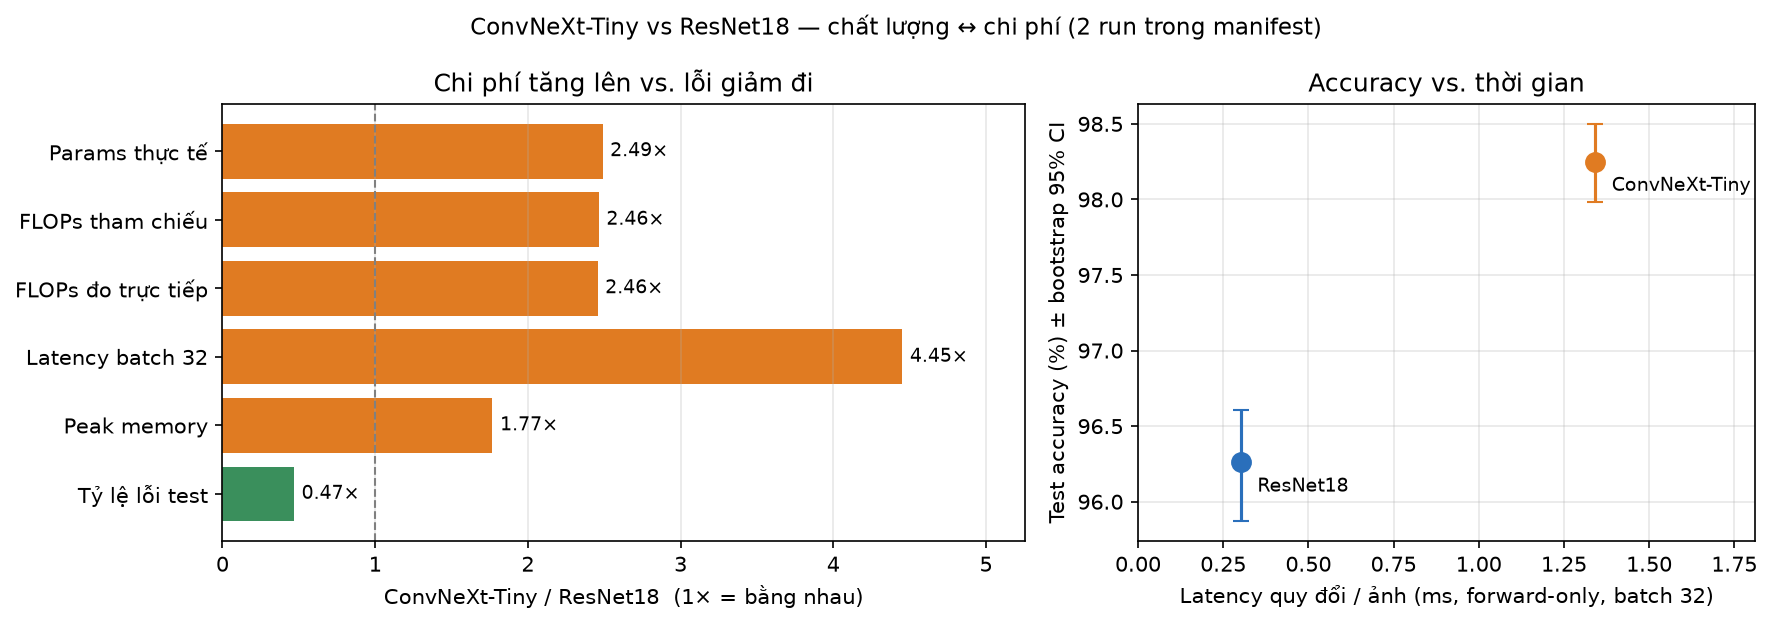

-> artifacts\comparison\quality_vs_cost.png


In [14]:
# --- hình: chi phí tăng bao nhiêu lần so với lỗi giảm bao nhiêu
labels, vals = [], []
for name, col in [("Params thực tế", "Params thực tế (M)"), ("FLOPs tham chiếu", "FLOPs tham chiếu ImageNet (G)"),
                  ("FLOPs đo trực tiếp", "FLOPs đo trực tiếp 2×MAC (G)"), ("Latency batch 32", lat_col),
                  ("Peak memory", "Peak mem (MB)")]:
    if pd.notna(cost.loc[C, col]) and pd.notna(cost.loc[R, col]):
        labels.append(name); vals.append(cost.loc[C, col] / cost.loc[R, col])
labels.append("Tỷ lệ lỗi test"); vals.append(err_c / err_r)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
colors = [COLORS[C]] * (len(vals) - 1) + ["#3a8f5c"]
bars = ax[0].barh(labels[::-1], vals[::-1], color=colors[::-1])
ax[0].axvline(1, color="gray", lw=1, ls="--")
for bar, v in zip(bars, vals[::-1]):
    ax[0].text(v + 0.05, bar.get_y() + bar.get_height() / 2, f"{v:.2f}×", va="center", fontsize=9)
ax[0].set_xlabel("ConvNeXt-Tiny / ResNet18  (1× = bằng nhau)")
ax[0].set_title("Chi phí tăng lên vs. lỗi giảm đi")
ax[0].set_xlim(0, max(vals) * 1.18); ax[0].grid(axis="x", alpha=0.3)

per_img = {m: cost.loc[m, "Latency quy đổi/ảnh (ms)"] for m in MODELS}
for m, a, (lo, hi) in ((R, acc_r, ci_r), (C, acc_c, ci_c)):
    ax[1].errorbar(per_img[m], a * 100, yerr=[[a * 100 - lo * 100], [hi * 100 - a * 100]], fmt="o", ms=9,
                   color=COLORS[m], capsize=4, label=LABELS[m])
    ax[1].annotate(LABELS[m], (per_img[m], a * 100), textcoords="offset points", xytext=(8, -14), fontsize=9)
ax[1].set_xlabel("Latency quy đổi / ảnh (ms, forward-only, batch 32)")
ax[1].set_ylabel("Test accuracy (%) ± bootstrap 95% CI")
ax[1].set_title("Accuracy vs. thời gian"); ax[1].grid(alpha=0.3)
ax[1].set_xlim(0, max(per_img.values()) * 1.35)
fig.suptitle("ConvNeXt-Tiny vs ResNet18 — chất lượng ↔ chi phí (2 run trong manifest)", fontsize=11)
fig.tight_layout()
show_fig(fig, OUT / "comparison" / "quality_vs_cost.png")

## 9. Lớp dễ nhầm
Dùng confusion matrix đã lưu của từng run (`confusion_matrix.npy`, hàng = nhãn thật, cột = dự đoán):
cặp nhầm hay gặp nhất của mỗi model, cặp nhầm hai chiều (A↔B), và nơi ConvNeXt-Tiny thực sự giảm được lỗi.

In [15]:
CM = {m: np.load(OUT / "predictions" / RUNS[m] / "confusion_matrix.npy") for m in MODELS}
for m in MODELS:   # confusion matrix lưu phải khớp dự đoán lưu
    assert CM[m].sum() == n and int(np.trace(CM[m])) == int((PRED[m]["pred_labels"] == y).sum()), f"{m}: confusion matrix lưu không khớp dự đoán lưu"
K = len(CLASS_NAMES)


def top_confusions(cm, k=10):
    rows = []
    for i in range(K):
        for j in range(K):
            if i != j and cm[i, j] > 0:
                rows.append((CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j]), cm[i, j] / cm[i].sum() * 100))
    return (pd.DataFrame(rows, columns=["Nhãn thật", "Dự đoán", "Số ảnh", "% của lớp thật"])
              .sort_values("Số ảnh", ascending=False).head(k).reset_index(drop=True))

for m in MODELS:
    print(f"\nTop nhầm lẫn có hướng — {LABELS[m]}")
    display(top_confusions(CM[m]).round(2))

# --- cặp nhầm hai chiều (A↔B)
pair_rows = []
for i in range(K):
    for j in range(i + 1, K):
        pair_rows.append({"Cặp": f"{CLASS_NAMES[i]} ↔ {CLASS_NAMES[j]}",
                          "ResNet18": int(CM[R][i, j] + CM[R][j, i]),
                          "ConvNeXt-Tiny": int(CM[C][i, j] + CM[C][j, i])})
df_pairs = pd.DataFrame(pair_rows)
df_pairs["Giảm (ảnh)"] = df_pairs["ResNet18"] - df_pairs["ConvNeXt-Tiny"]
df_pairs["Giảm (%)"] = np.where(df_pairs["ResNet18"] > 0, df_pairs["Giảm (ảnh)"] / df_pairs["ResNet18"].replace(0, np.nan) * 100, np.nan)
print("\nCặp nhầm hai chiều — sắp theo ResNet18 (top 10):")
display(df_pairs.sort_values("ResNet18", ascending=False).head(10).reset_index(drop=True).round(1))

# --- lỗi trong nhóm / xuyên nhóm
VEHICLES = {"airplane", "automobile", "ship", "truck"}
def group_errors(cm):
    out = {"phương tiện → phương tiện": 0, "động vật → động vật": 0, "phương tiện ↔ động vật": 0}
    for i in range(K):
        for j in range(K):
            if i == j: continue
            vi, vj = CLASS_NAMES[i] in VEHICLES, CLASS_NAMES[j] in VEHICLES
            out["phương tiện → phương tiện" if vi and vj else "động vật → động vật" if (not vi and not vj) else "phương tiện ↔ động vật"] += int(cm[i, j])
    return out
df_group = pd.DataFrame({LABELS[m]: group_errors(CM[m]) for m in MODELS})
df_group["Tỷ trọng ResNet18 (%)"] = df_group["ResNet18"] / df_group["ResNet18"].sum() * 100
df_group["Tỷ trọng ConvNeXt-Tiny (%)"] = df_group["ConvNeXt-Tiny"] / df_group["ConvNeXt-Tiny"].sum() * 100
print("\nLỗi theo nhóm (phương tiện: airplane, automobile, ship, truck; còn lại là động vật):")
display(df_group.round(1))


Top nhầm lẫn có hướng — ResNet18


,Nhãn thật,Dự đoán,Số ảnh,% của lớp thật
0,cat,dog,53,5.3
1,dog,cat,40,4.0
2,automobile,truck,20,2.0
3,truck,automobile,19,1.9
4,bird,cat,13,1.3
5,bird,frog,13,1.3
6,bird,deer,13,1.3
7,airplane,ship,12,1.2
8,cat,deer,12,1.2
9,cat,bird,10,1.0



Top nhầm lẫn có hướng — ConvNeXt-Tiny


,Nhãn thật,Dự đoán,Số ảnh,% của lớp thật
0,dog,cat,27,2.7
1,cat,dog,20,2.0
2,automobile,truck,14,1.4
3,truck,automobile,10,1.0
4,ship,airplane,8,0.8
5,dog,horse,6,0.6
6,ship,truck,5,0.5
7,deer,bird,5,0.5
8,cat,deer,5,0.5
9,airplane,ship,5,0.5



Cặp nhầm hai chiều — sắp theo ResNet18 (top 10):


,Cặp,ResNet18,ConvNeXt-Tiny,Giảm (ảnh),Giảm (%)
0,cat ↔ dog,93,47,46,49.5
1,automobile ↔ truck,39,24,15,38.5
2,bird ↔ cat,23,9,14,60.9
3,airplane ↔ ship,19,13,6,31.6
4,bird ↔ deer,17,8,9,52.9
5,dog ↔ horse,17,8,9,52.9
6,bird ↔ frog,17,8,9,52.9
7,cat ↔ deer,16,7,9,56.2
8,cat ↔ frog,16,5,11,68.8
9,deer ↔ dog,14,4,10,71.4



Lỗi theo nhóm (phương tiện: airplane, automobile, ship, truck; còn lại là động vật):


,ResNet18,ConvNeXt-Tiny,Tỷ trọng ResNet18 (%),Tỷ trọng ConvNeXt-Tiny (%)
phương tiện → phương tiện,81,52,21.7,29.7
động vật → động vật,253,111,67.6,63.4
phương tiện ↔ động vật,40,12,10.7,6.9


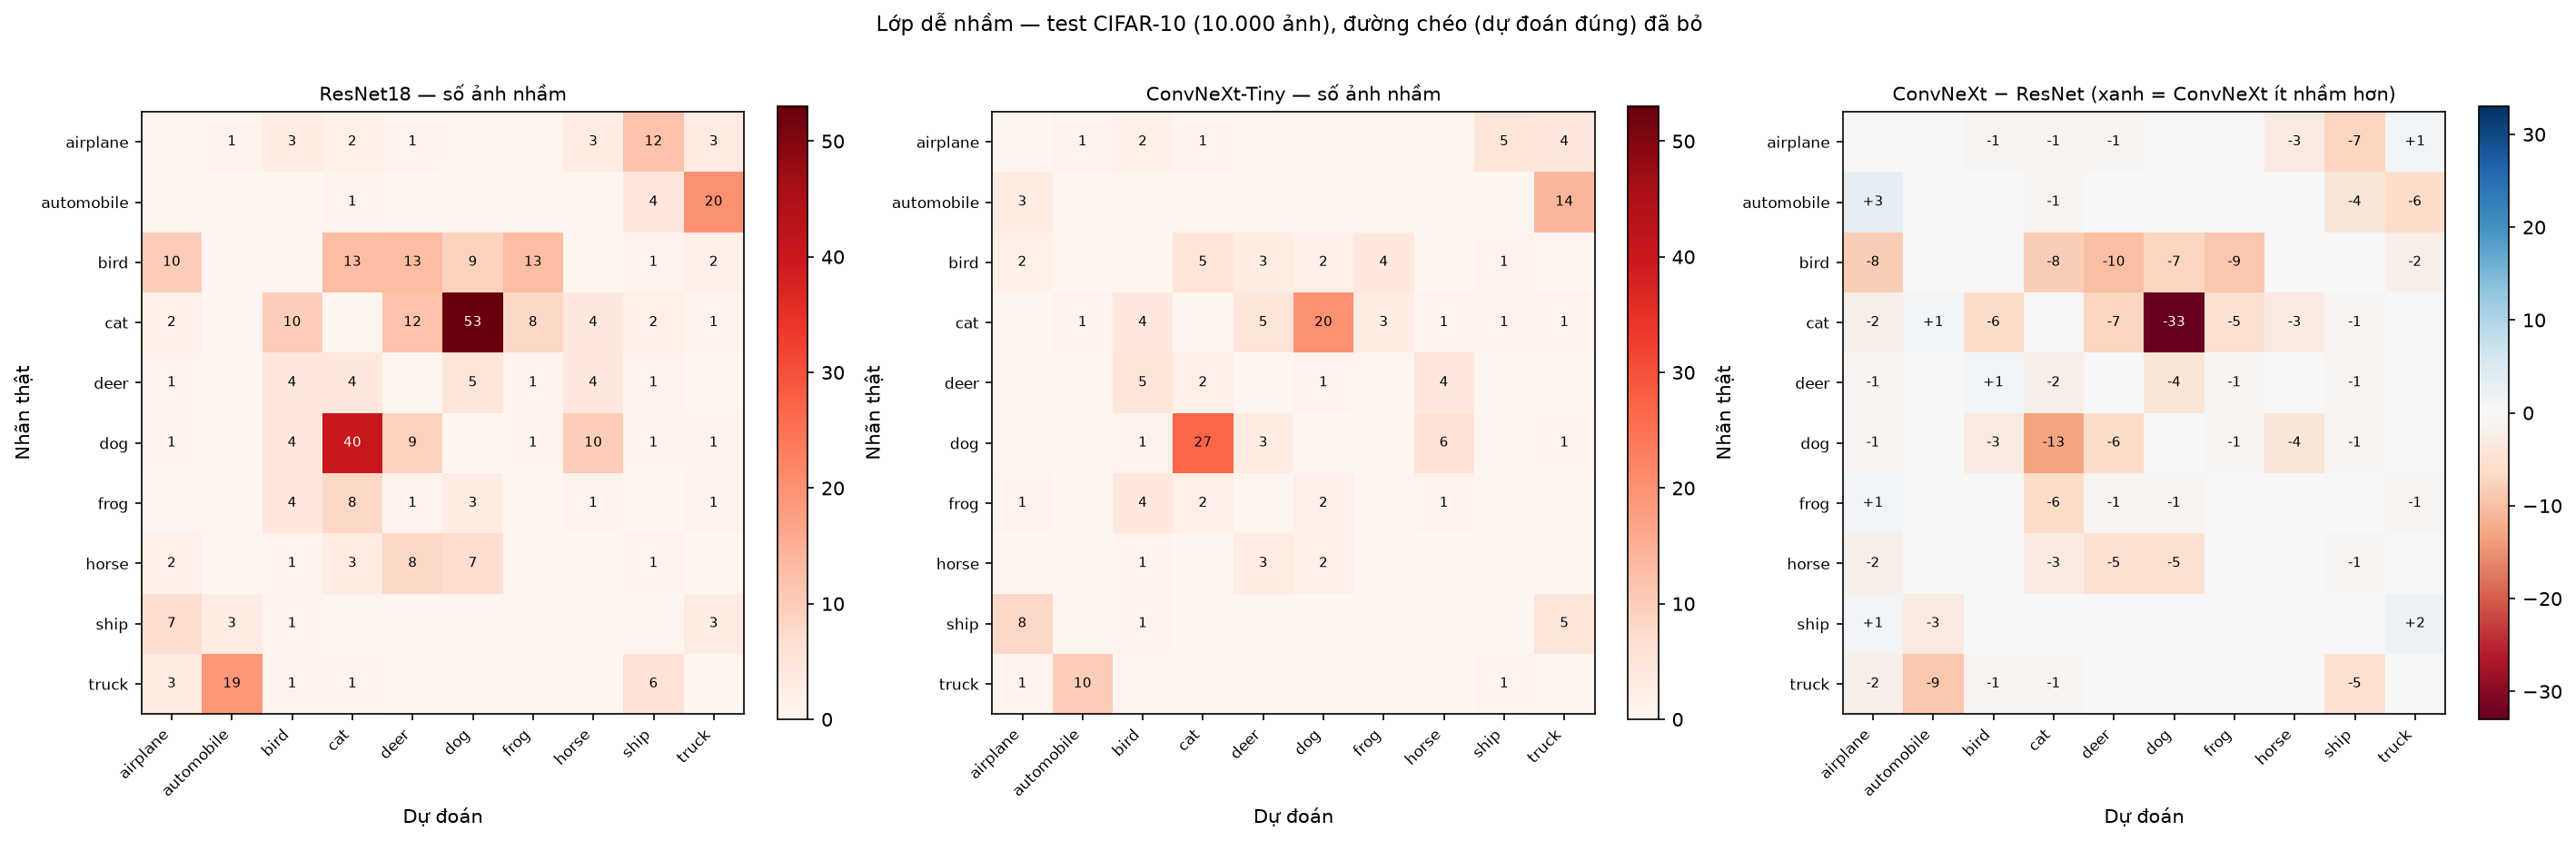

-> artifacts\comparison\confusion_errors_side_by_side.png


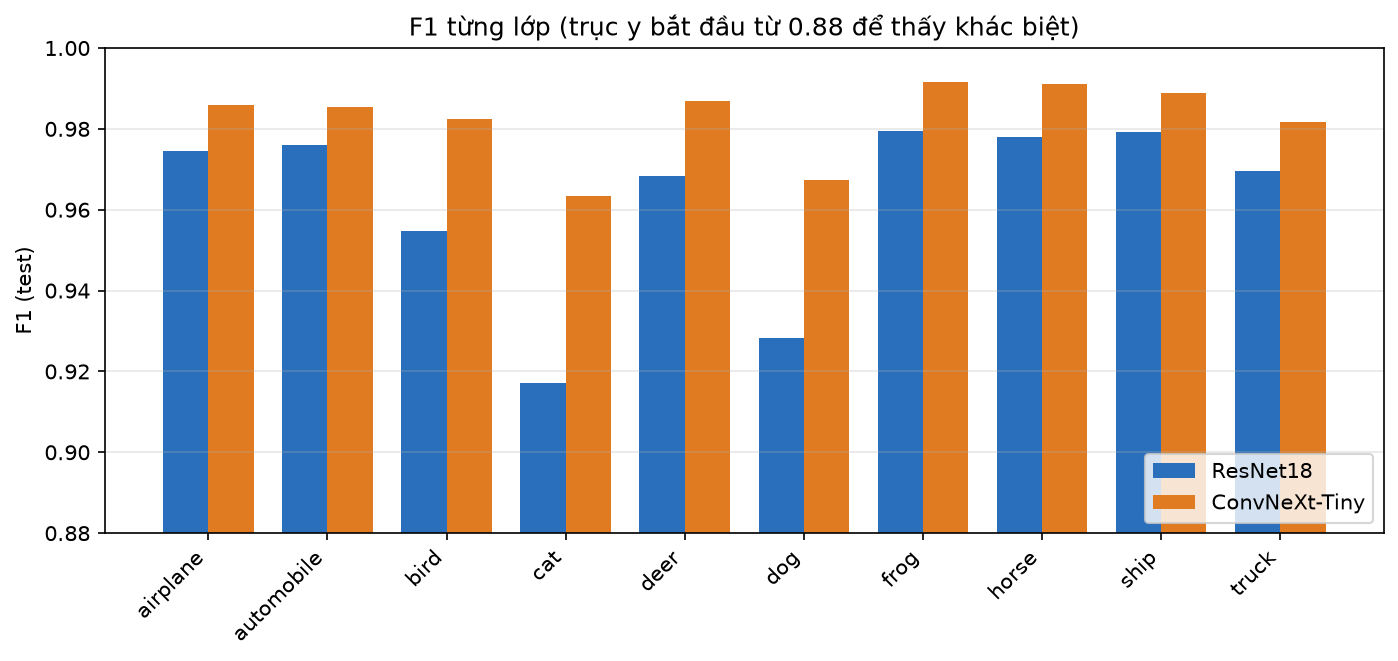

-> artifacts\comparison\per_class_f1_both.png
3 lớp F1 thấp nhất — ResNet18: ['cat', 'dog', 'bird'] | ConvNeXt-Tiny: ['cat', 'dog', 'truck']
Lớp được cải thiện F1 nhiều nhất: cat (+0.046) | ít nhất: automobile (+0.009)


In [16]:
# --- hình: ma trận lỗi (đường chéo = 0) cho từng model + hiệu hai model
def off_diag(cm):
    e = cm.astype(float).copy(); np.fill_diagonal(e, 0); return e

E_r, E_c = off_diag(CM[R]), off_diag(CM[C])
vmax = max(E_r.max(), E_c.max())
diff = E_c - E_r
dmax = np.abs(diff).max()

fig, axes = plt.subplots(1, 3, figsize=(19, 6.2))
for ax, E, title, cmap, vlo, vhi in ((axes[0], E_r, "ResNet18 — số ảnh nhầm", "Reds", 0, vmax),
                                      (axes[1], E_c, "ConvNeXt-Tiny — số ảnh nhầm", "Reds", 0, vmax),
                                      (axes[2], diff, "ConvNeXt − ResNet (xanh = ConvNeXt ít nhầm hơn)", "RdBu", -dmax, dmax)):
    im = ax.imshow(E, cmap=cmap, vmin=vlo, vmax=vhi)
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn thật"); ax.set_title(title, fontsize=10)
    for i in range(K):
        for j in range(K):
            v = E[i, j]
            if v != 0 and i != j:
                ax.text(j, i, f"{v:+.0f}" if E is diff else f"{v:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(v) > 0.55 * vhi else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Lớp dễ nhầm — test CIFAR-10 (10.000 ảnh), đường chéo (dự đoán đúng) đã bỏ", fontsize=11)
fig.tight_layout()
show_fig(fig, OUT / "comparison" / "confusion_errors_side_by_side.png")

# --- hình: F1 từng lớp hai model
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(K); w = 0.38
ax.bar(x - w / 2, pc["F1_resnet18"], w, label="ResNet18", color=COLORS[R])
ax.bar(x + w / 2, pc["F1_convnext"], w, label="ConvNeXt-Tiny", color=COLORS[C])
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylim(0.88, 1.0); ax.set_ylabel("F1 (test)"); ax.grid(axis="y", alpha=0.3); ax.legend(loc="lower right")
ax.set_title("F1 từng lớp (trục y bắt đầu từ 0.88 để thấy khác biệt)")
show_fig(fig, OUT / "comparison" / "per_class_f1_both.png")

hard = pc["F1_resnet18"].nsmallest(3).index.tolist(), pc["F1_convnext"].nsmallest(3).index.tolist()
print("3 lớp F1 thấp nhất — ResNet18:", hard[0], "| ConvNeXt-Tiny:", hard[1])
print("Lớp được cải thiện F1 nhiều nhất:", pc["ΔF1 (ConvNeXt − ResNet)"].idxmax(), f"({pc['ΔF1 (ConvNeXt − ResNet)'].max():+.3f})",
      "| ít nhất:", pc["ΔF1 (ConvNeXt − ResNet)"].idxmin(), f"({pc['ΔF1 (ConvNeXt − ResNet)'].min():+.3f})")

## 10. Ví dụ lỗi của hai model
Ảnh gốc 32×32 lấy từ test set (phóng to bằng nearest để không làm mờ). Notebook kiểm tra `index` trong file dự đoán **khớp nhãn thật** của dataset trước khi vẽ.
Ba nhóm: *cả hai cùng sai*, *chỉ ResNet18 sai*, *chỉ ConvNeXt-Tiny sai* — mỗi nhóm xếp theo confidence của model sai (cao → thấp).

{'both_wrong': 113, 'only_resnet_wrong': 261, 'only_convnext_wrong': 62}
Trong 113 ảnh cả hai sai: 88 ảnh hai model đoán CÙNG một nhãn sai (dấu hiệu ảnh mơ hồ / nhãn nhiễu / lỗi hệ thống).


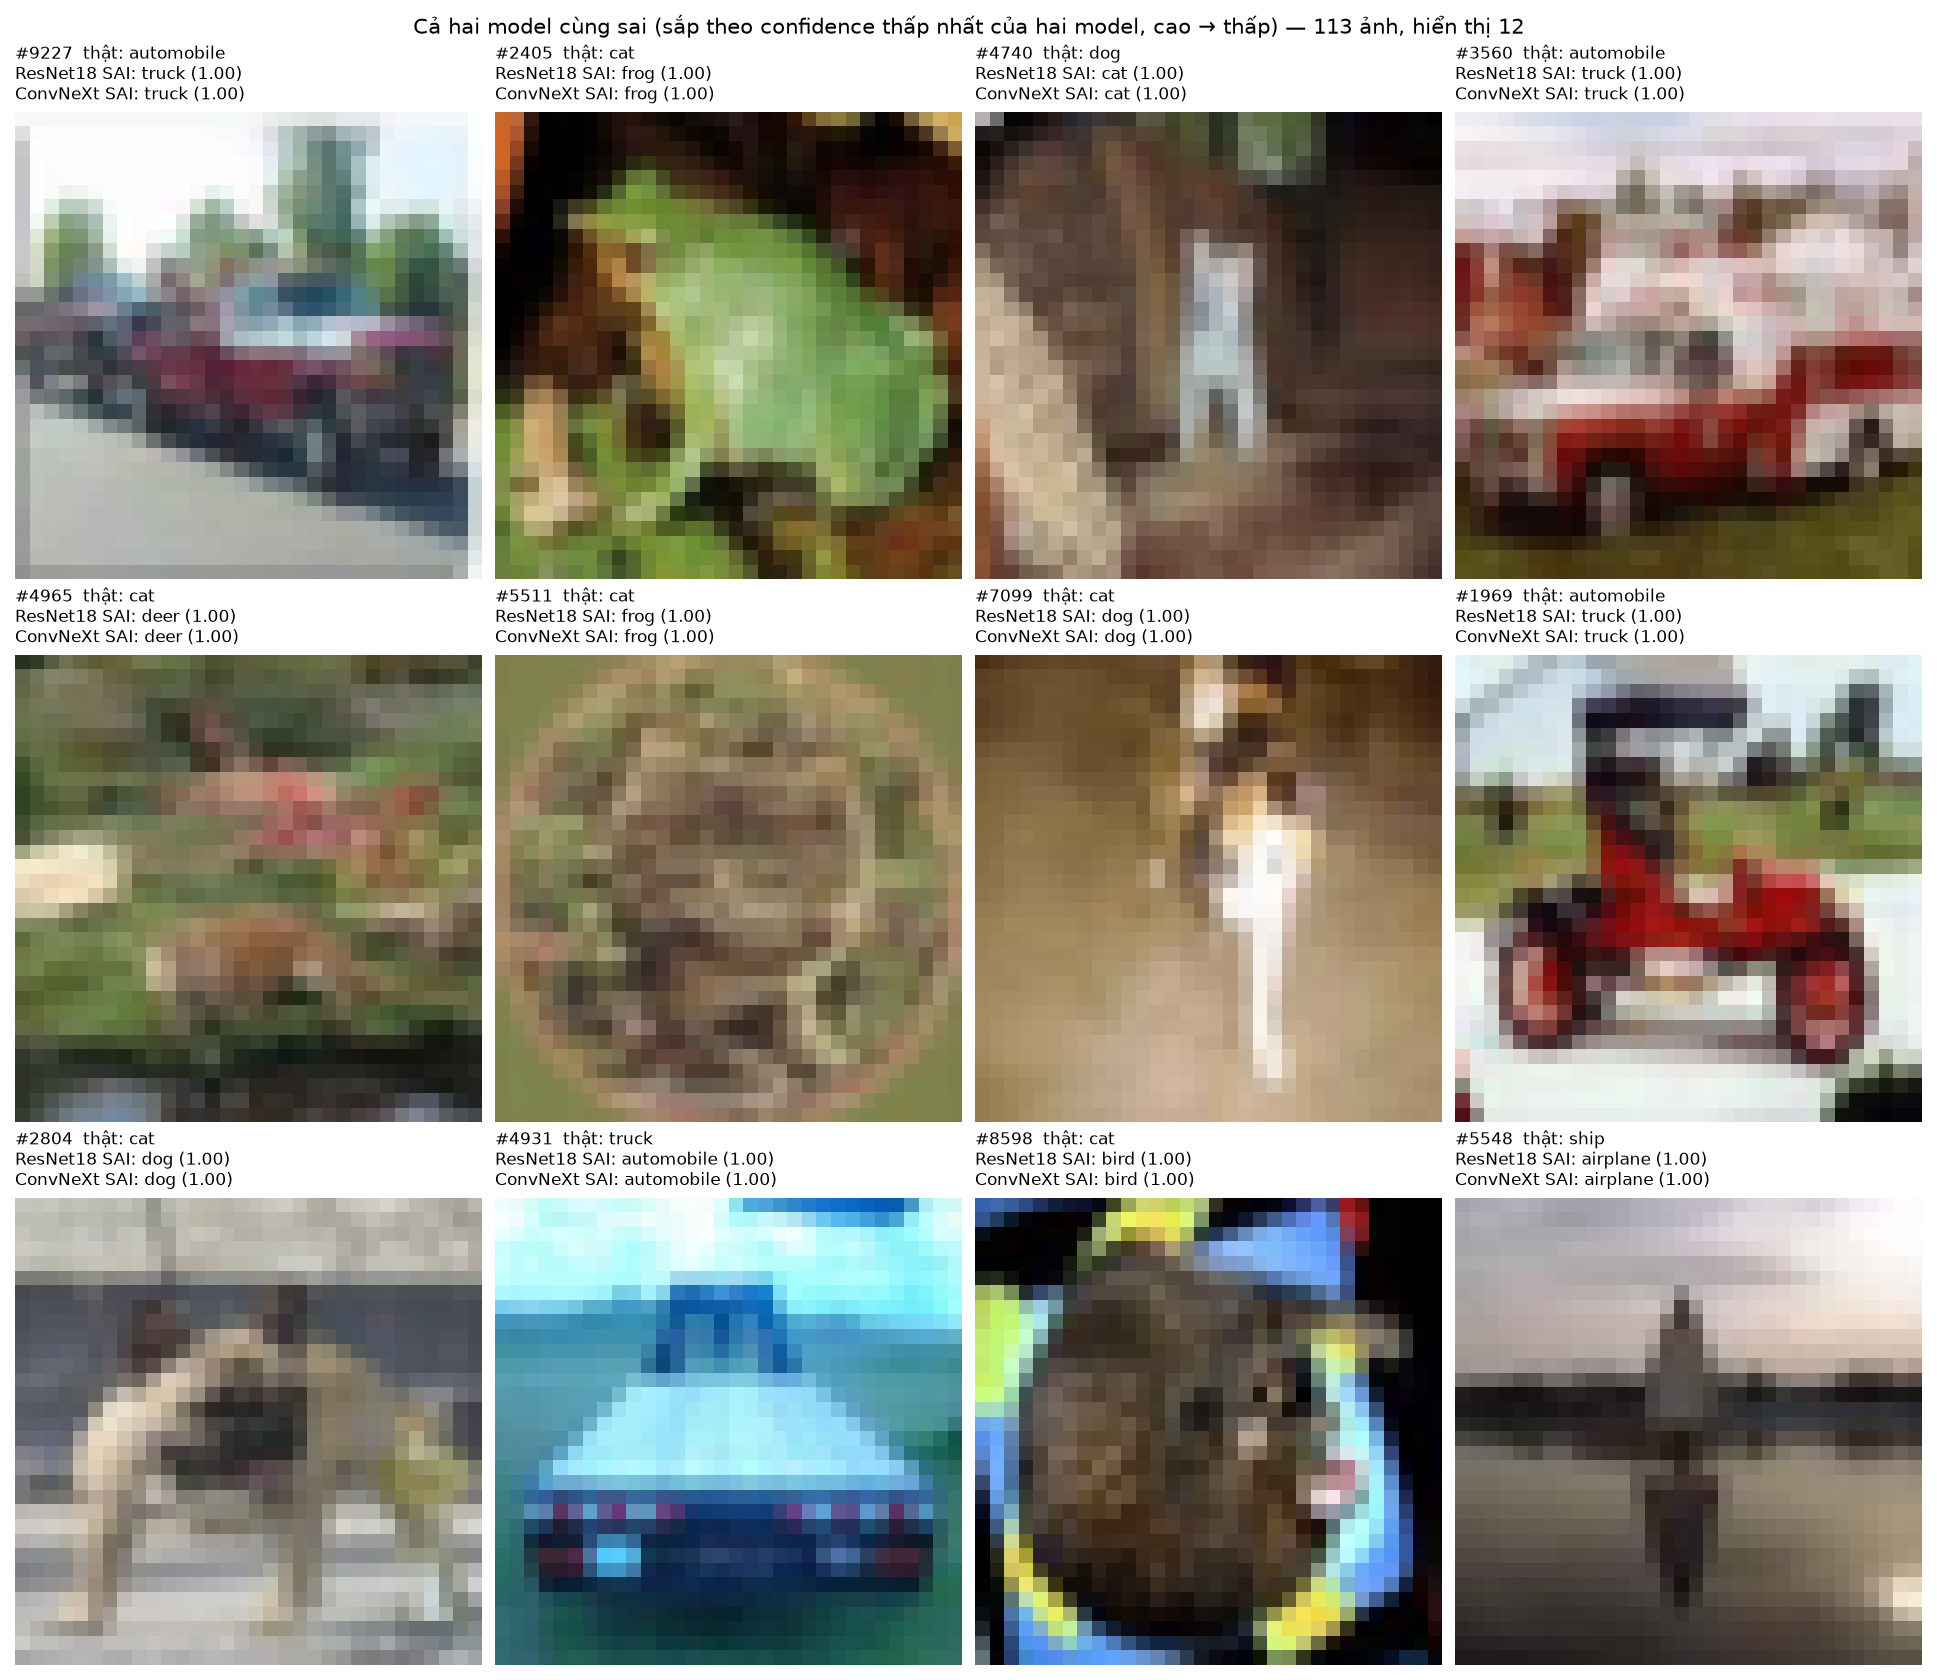

-> artifacts\comparison\errors_both_wrong.png


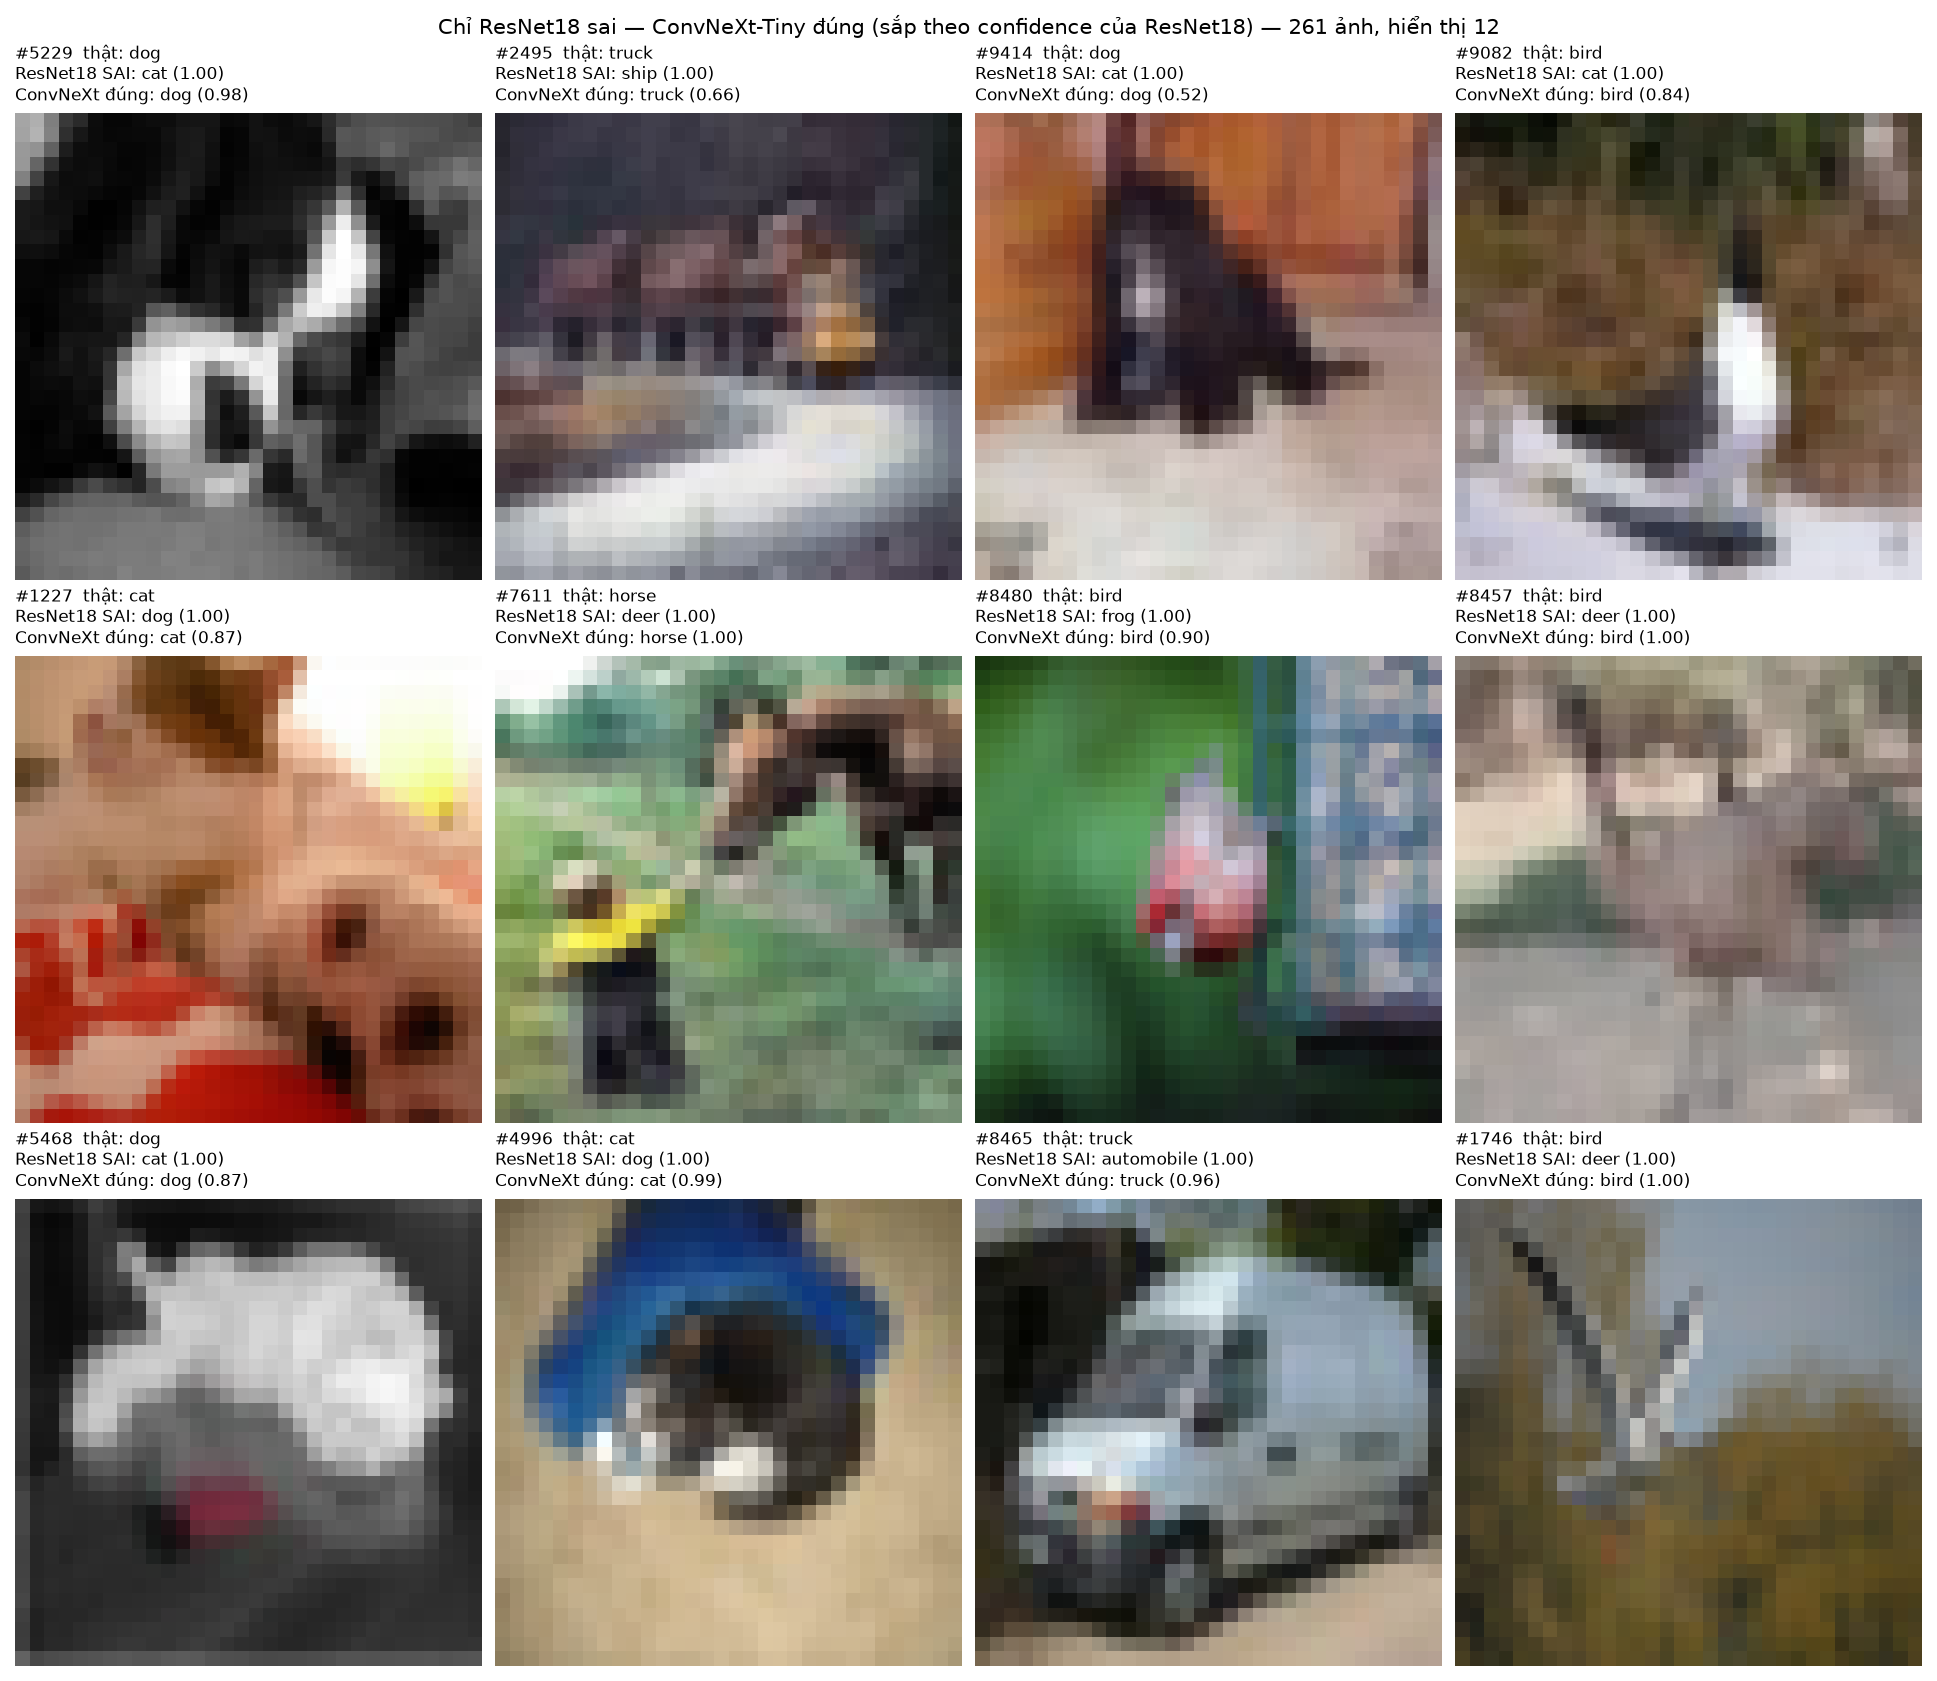

-> artifacts\comparison\errors_only_resnet_wrong.png


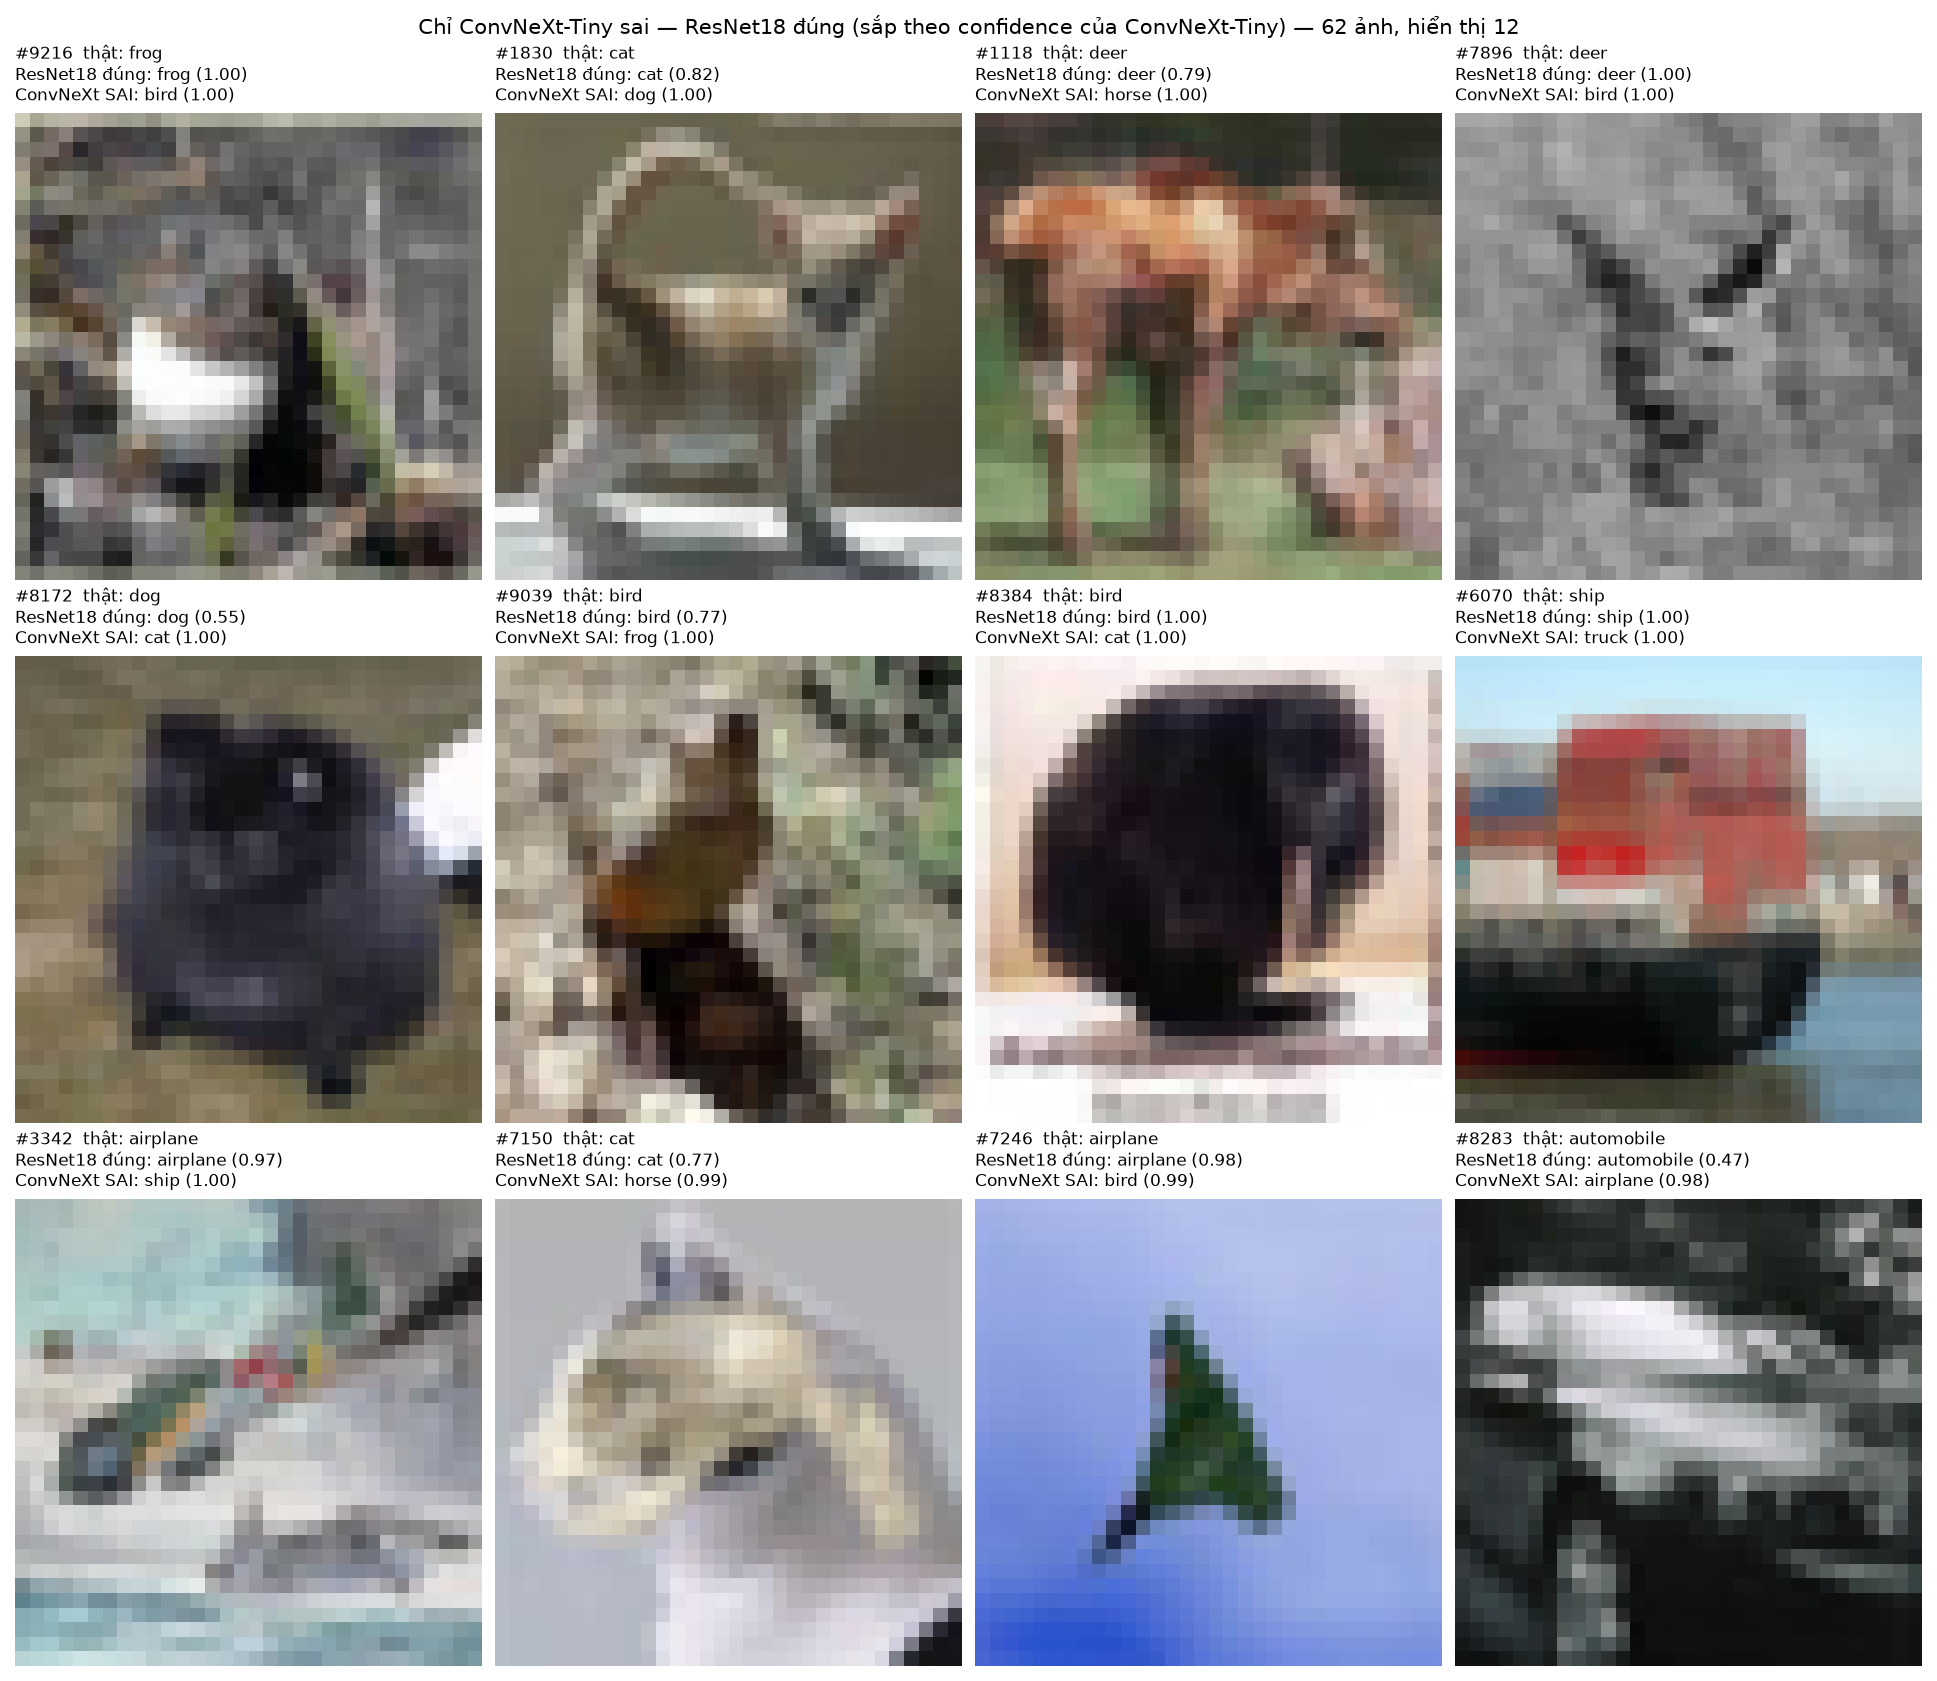

-> artifacts\comparison\errors_only_convnext_wrong.png


In [17]:
test_raw = CIFAR10(config["data_root"], train=False, download=False)      # PIL 32x32, không transform
assert list(test_raw.classes) == CLASS_NAMES
assert np.array_equal(np.array(test_raw.targets)[r["indices"]], y), "index trong dự đoán không khớp nhãn thật của CIFAR-10 test"

pos = np.arange(n)
groups = {
    "both_wrong":         pos[~ok_r & ~ok_c],
    "only_resnet_wrong":  pos[~ok_r & ok_c],
    "only_convnext_wrong": pos[ok_r & ~ok_c],
}
same_label = int((r["pred_labels"][groups["both_wrong"]] == c["pred_labels"][groups["both_wrong"]]).sum())
print({k: len(v) for k, v in groups.items()})
print(f"Trong {len(groups['both_wrong'])} ảnh cả hai sai: {same_label} ảnh hai model đoán CÙNG một nhãn sai "
      f"(dấu hiệu ảnh mơ hồ / nhãn nhiễu / lỗi hệ thống).")

TITLES = {"both_wrong": "Cả hai model cùng sai (sắp theo confidence thấp nhất của hai model, cao → thấp)",
          "only_resnet_wrong": "Chỉ ResNet18 sai — ConvNeXt-Tiny đúng (sắp theo confidence của ResNet18)",
          "only_convnext_wrong": "Chỉ ConvNeXt-Tiny sai — ResNet18 đúng (sắp theo confidence của ConvNeXt-Tiny)"}

def draw_group(key, k=12, cols=4):
    p = groups[key]
    if len(p) == 0:
        print(f"[{key}] không có ảnh."); return
    if key == "both_wrong":
        score = np.minimum(r["confidences"][p], c["confidences"][p])
    elif key == "only_resnet_wrong":
        score = r["confidences"][p]
    else:
        score = c["confidences"][p]
    sel = p[np.argsort(-score)[:k]]
    rows = (len(sel) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.2, rows * 3.7), layout="constrained")
    axes = np.array(axes).reshape(-1)
    for a in axes: a.axis("off")
    for a, q in zip(axes, sel):
        img, _ = test_raw[int(r["indices"][q])]
        a.imshow(img, interpolation="nearest")
        rt = CLASS_NAMES[r["pred_labels"][q]]; ct = CLASS_NAMES[c["pred_labels"][q]]
        ok_txt = lambda ok: "đúng:" if ok else "SAI:"
        a.set_title(f"#{int(r['indices'][q])}  thật: {CLASS_NAMES[y[q]]}\n"
                    f"ResNet18 {ok_txt(ok_r[q])} {rt} ({r['confidences'][q]:.2f})\n"
                    f"ConvNeXt {ok_txt(ok_c[q])} {ct} ({c['confidences'][q]:.2f})",
                    fontsize=8, loc="left",
                    color="black")
    fig.suptitle(f"{TITLES[key]} — {len(p)} ảnh, hiển thị {len(sel)}", fontsize=10)
    show_fig(fig, OUT / "comparison" / f"errors_{key}.png")

for key in groups:
    draw_group(key)

In [18]:
# --- bảng ví dụ lỗi (để dẫn index vào báo cáo) + nhãn nhầm phổ biến trong từng nhóm
def group_table(key, k=10):
    p = groups[key]
    if len(p) == 0: return pd.DataFrame()
    score = (np.minimum(r["confidences"][p], c["confidences"][p]) if key == "both_wrong"
             else r["confidences"][p] if key == "only_resnet_wrong" else c["confidences"][p])
    sel = p[np.argsort(-score)[:k]]
    return pd.DataFrame({
        "index test": r["indices"][sel],
        "Nhãn thật": [CLASS_NAMES[i] for i in y[sel]],
        "ResNet18 dự đoán": [CLASS_NAMES[i] for i in r["pred_labels"][sel]],
        "ResNet18 conf": r["confidences"][sel].round(3),
        "ConvNeXt dự đoán": [CLASS_NAMES[i] for i in c["pred_labels"][sel]],
        "ConvNeXt conf": c["confidences"][sel].round(3),
    })

for key in groups:
    print(f"\n{TITLES[key]}")
    display(group_table(key))

# Confidence trung bình khi sai: model nào "tự tin sai" hơn?
for m in MODELS:
    wrong = PRED[m]["pred_labels"] != y
    print(f"{LABELS[m]:14s} confidence TB khi sai = {PRED[m]['confidences'][wrong].mean():.3f} | khi đúng = {PRED[m]['confidences'][~wrong].mean():.3f} "
          f"| số lỗi conf ≥ 0.9: {int((PRED[m]['confidences'][wrong] >= 0.9).sum())}/{int(wrong.sum())}")


Cả hai model cùng sai (sắp theo confidence thấp nhất của hai model, cao → thấp)


,index test,Nhãn thật,ResNet18 dự đoán,ResNet18 conf,ConvNeXt dự đoán,ConvNeXt conf
0,9227,automobile,truck,1.000,truck,1.000
1,2405,cat,frog,1.000,frog,1.000
2,4740,dog,cat,1.000,cat,1.000
3,3560,automobile,truck,1.000,truck,1.000
4,4965,cat,deer,1.000,deer,0.999
5,5511,cat,frog,0.999,frog,0.999
6,7099,cat,dog,0.999,dog,1.000
7,1969,automobile,truck,1.000,truck,0.999
8,2804,cat,dog,0.999,dog,1.000
9,4931,truck,automobile,1.000,automobile,0.999



Chỉ ResNet18 sai — ConvNeXt-Tiny đúng (sắp theo confidence của ResNet18)


,index test,Nhãn thật,ResNet18 dự đoán,ResNet18 conf,ConvNeXt dự đoán,ConvNeXt conf
0,5229,dog,cat,1.000,dog,0.983
1,2495,truck,ship,0.999,truck,0.659
2,9414,dog,cat,0.999,dog,0.521
3,9082,bird,cat,0.999,bird,0.836
4,1227,cat,dog,0.999,cat,0.869
5,7611,horse,deer,0.999,horse,0.999
6,8480,bird,frog,0.999,bird,0.904
7,8457,bird,deer,0.999,bird,0.996
8,5468,dog,cat,0.999,dog,0.869
9,4996,cat,dog,0.998,cat,0.988



Chỉ ConvNeXt-Tiny sai — ResNet18 đúng (sắp theo confidence của ConvNeXt-Tiny)


,index test,Nhãn thật,ResNet18 dự đoán,ResNet18 conf,ConvNeXt dự đoán,ConvNeXt conf
0,9216,frog,frog,0.998,bird,1.000
1,1830,cat,cat,0.824,dog,1.000
2,1118,deer,deer,0.793,horse,0.999
3,7896,deer,deer,1.000,bird,0.998
4,8172,dog,dog,0.545,cat,0.998
5,9039,bird,bird,0.769,frog,0.997
6,8384,bird,bird,1.000,cat,0.997
7,6070,ship,ship,0.998,truck,0.995
8,3342,airplane,airplane,0.971,ship,0.995
9,7150,cat,cat,0.766,horse,0.993


ResNet18       confidence TB khi sai = 0.797 | khi đúng = 0.990 | số lỗi conf ≥ 0.9: 154/374
ConvNeXt-Tiny  confidence TB khi sai = 0.836 | khi đúng = 0.996 | số lỗi conf ≥ 0.9: 89/175


## 11. Bảng tổng hợp cuối và nhận xét cơ học
Bảng lưu ở `artifacts/comparison_table.csv` (kèm run, epoch, SHA256 checkpoint để truy nguyên). Nhận xét bên dưới chỉ là tóm tắt số liệu;
phần giải thích nguyên nhân cần viết trong báo cáo.

In [19]:
df_final = df_test[["Test Accuracy", "Macro-F1", "Test Loss"]].join(df_cost)
df_final.insert(0, "Run", pd.Series(RUNS))
df_final.insert(1, "Best epoch", pd.Series({m: int(by_model[m]["best_epoch"]) for m in MODELS}))
df_final.insert(2, "best.pt SHA256 (12 ký tự đầu)", pd.Series({m: CKPT_SHA[m][:12] for m in MODELS}))
print("BẢNG TỔNG HỢP: HIỆU NĂNG vs CHI PHÍ (2 run trong manifest)")
display(df_final.round(4).T)

out_csv = OUT / "comparison_table.csv"
df_final.to_csv(out_csv, encoding="utf-8-sig")
(OUT / "comparison").mkdir(parents=True, exist_ok=True)
tradeoff.to_csv(OUT / "comparison" / "tradeoff.csv", encoding="utf-8-sig")
df_pairs.sort_values("ResNet18", ascending=False).to_csv(OUT / "comparison" / "confusable_pairs.csv", index=False, encoding="utf-8-sig")
pc.to_csv(OUT / "comparison" / "per_class_metrics.csv", encoding="utf-8-sig")
print(f"\n✓ Đã lưu {out_csv} và các bảng trong {OUT / 'comparison'}")

top_pair_r = df_pairs.sort_values("ResNet18", ascending=False).iloc[0]
top_pair_c = df_pairs.sort_values("ConvNeXt-Tiny", ascending=False).iloc[0]
print("\nNHẬN XÉT NHANH (cơ học)")
print(f"- Accuracy: ConvNeXt-Tiny {acc_c:.4f} vs ResNet18 {acc_r:.4f} ({d_acc_pp:+.2f} điểm %, giảm lỗi {extra['Giảm lỗi tương đối (%)']:.1f}%; McNemar p={p_mcnemar:.3g}).")
print(f"- Chi phí (ConvNeXt/ResNet): params ×{tradeoff.loc['Params thực tế (M)', 'ConvNeXt / ResNet (×)']:.2f}, "
      f"FLOPs tham chiếu ×{tradeoff.loc['FLOPs tham chiếu (G)', 'ConvNeXt / ResNet (×)']:.2f}, "
      f"latency batch ×{tradeoff.loc[lat_col, 'ConvNeXt / ResNet (×)']:.2f}, "
      f"peak mem ×{tradeoff.loc['Peak mem (MB)', 'ConvNeXt / ResNet (×)']:.2f}.")
print(f"- Cặp nhầm nhiều nhất: ResNet18 = {top_pair_r['Cặp']} ({int(top_pair_r['ResNet18'])} ảnh); "
      f"ConvNeXt-Tiny = {top_pair_c['Cặp']} ({int(top_pair_c['ConvNeXt-Tiny'])} ảnh).")
print(f"- Lớp F1 thấp nhất: ResNet18 = {pc['F1_resnet18'].idxmin()} ({pc['F1_resnet18'].min():.3f}); ConvNeXt-Tiny = {pc['F1_convnext'].idxmin()} ({pc['F1_convnext'].min():.3f}).")
print(f"- Cả hai cùng sai: {both_bad} ảnh; chỉ ResNet18 sai: {cc}; chỉ ConvNeXt-Tiny sai: {b}.")

BẢNG TỔNG HỢP: HIỆU NĂNG vs CHI PHÍ (2 run trong manifest)


Model,resnet18,convnext_tiny
Run,resnet18_seed42_20261117_175014_404116,convnext_tiny_seed42_20261117_191514_964199
Best epoch,10,9
best.pt SHA256 (12 ký tự đầu),9de917e947a6,07726f08f96c
Test Accuracy,0.9626,0.9825
Macro-F1,0.9625,0.9825
Test Loss,0.139,0.0706
Params thực tế (M),11.1816,27.8278
FLOPs tham chiếu ImageNet (G),1.81,4.46
FLOPs đo trực tiếp 2×MAC (G),3.6271,8.9095
Latency/batch 32 mean (ms),9.6427,42.9262



✓ Đã lưu artifacts\comparison_table.csv và các bảng trong artifacts\comparison

NHẬN XÉT NHANH (cơ học)
- Accuracy: ConvNeXt-Tiny 0.9825 vs ResNet18 0.9626 (+1.99 điểm %, giảm lỗi 53.2%; McNemar p=3.44e-30).
- Chi phí (ConvNeXt/ResNet): params ×2.49, FLOPs tham chiếu ×2.46, latency batch ×4.45, peak mem ×1.77.
- Cặp nhầm nhiều nhất: ResNet18 = cat ↔ dog (93 ảnh); ConvNeXt-Tiny = cat ↔ dog (47 ảnh).
- Lớp F1 thấp nhất: ResNet18 = cat (0.917); ConvNeXt-Tiny = cat (0.964).
- Cả hai cùng sai: 113 ảnh; chỉ ResNet18 sai: 261; chỉ ConvNeXt-Tiny sai: 62.
